# Course Generation Algorithm — Hackable Notebook

Reimplements Lectura's lecture-generation pipeline (**handbook course → lecture plan → per-lecture outline/slides/Bloom**)
as a plain, editable script for prompt-engineering experiments.

- **Step 0** loads the MSc handbook PDF and lets you pick a course section (default: **4.1 Software Engineering Modules**, from page 23).
- **Step 0.5** extracts or generates **10–12 lectures**, saves JSON + Markdown.
- **Steps 1–3** define outline / slides / Bloom prompts and generators.
- **Step 3.5** improves problem slides and re-evaluates Bloom (target **95**, max **3** rounds). Saves **publication-quality figures** (PDF/PNG/SVG).
- **Step 5** computes **CQI v1** (lecture readiness + course quality index with breakdown).
- **Step 4** loops over every lecture: outline → slides → Bloom → improve → CQI; saves JSON + PDF report.
- One `call_llm()` function talks to **OpenRouter** or **Anthropic** (from `.env`).
- Bloom improve logic mirrors `src/lib/bloom/problem-slides.ts` and `src/server/services/bloom-improve.ts`.
- CQI v1 code remains in Step 5 for reference (`src/lib/cqi/v1.ts`) but is not run by default.

Run cells top to bottom.

In [1]:
import json
import os
import re
import subprocess
import sys
import time
from pathlib import Path

import requests
from IPython.display import HTML, display

NOTEBOOK_DIR = Path.cwd()


def _load_dotenv(path: Path) -> None:
    if not path.exists():
        return
    for line in path.read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        key, _, value = line.partition("=")
        key = key.strip()
        value = value.strip().strip('"').strip("'")
        if key and key not in os.environ:
            os.environ[key] = value


_load_dotenv(NOTEBOOK_DIR / ".env")

OPENROUTER_API_KEY = os.environ.get("OPENROUTER_API_KEY", "")
ANTHROPIC_API_KEY = os.environ.get("ANTHROPIC_API_KEY", "")
LLM_PROVIDER = "openrouter" if OPENROUTER_API_KEY else "anthropic" if ANTHROPIC_API_KEY else ""
if not LLM_PROVIDER:
    raise EnvironmentError(
        "Set OPENROUTER_API_KEY or ANTHROPIC_API_KEY in the environment or .env file."
    )

# OpenRouter slug; Anthropic fallback maps this to ANTHROPIC_TEXT_MODEL.
MODEL = "anthropic/claude-sonnet-4.5"
print(f"LLM provider: {LLM_PROVIDER} | model: {MODEL}")

LLM provider: anthropic | model: anthropic/claude-sonnet-4.5


## Step 0 — Course selection from CSSE Handbook

Reads `CSSE_MSc_Handbook_ Fall 2025_V1_3.pdf` from the project root and extracts the selected course section.

**Change your course:** edit `SELECTED_COURSE_ID` (and optionally `SELECTED_MODULE_CODE`) in the next cell, then re-run it.

| ID | Section | Pages |
|----|---------|-------|
| `4.1` | Software Engineering Modules | 23–35 |
| `4.2` | Cybersecurity Modules | 36–49 |
| `4.3` | Artificial Intelligence Modules | 50–59 |

More sections can be added to `HANDBOOK_SECTIONS` as you expand experiments.

In [2]:
# --- Handbook & course selection (edit these) ---
HANDBOOK_FILENAME = "CSSE_MSc_Handbook_ Fall 2025_V1_3.pdf"
SELECTED_COURSE_ID = "4.1"  # e.g. "4.2" Cybersecurity, "4.3" AI
SELECTED_MODULE_CODE = None  # e.g. "2025-MCSSE-SE-01"; None = first module in section

HANDBOOK_SECTIONS = {
    "4.1": {
        "title": "Software Engineering Modules",
        "start_page": 23,
        "end_page": 35,
    },
    "4.2": {
        "title": "Cybersecurity Modules",
        "start_page": 36,
        "end_page": 49,
    },
    "4.3": {
        "title": "Artificial Intelligence Modules",
        "start_page": 50,
        "end_page": 59,
    },
}


def _ensure_pypdf():
    try:
        from pypdf import PdfReader  # type: ignore
        return PdfReader
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "pypdf", "-q"])
        from pypdf import PdfReader  # type: ignore
        return PdfReader


def extract_handbook_pages(pdf_path: Path, start_page: int, end_page: int) -> str:
    """Extract text from inclusive 1-based PDF page range."""
    PdfReader = _ensure_pypdf()
    reader = PdfReader(str(pdf_path))
    chunks: list[str] = []
    for page_num in range(start_page, min(end_page, len(reader.pages)) + 1):
        text = reader.pages[page_num - 1].extract_text() or ""
        chunks.append(f"--- Page {page_num} ---\n{text.strip()}")
    return "\n\n".join(chunks)


def parse_handbook_modules(section_text: str) -> list[dict]:
    """Parse module blocks from a handbook section (Module Name / Module Code / ECTS)."""
    modules: list[dict] = []
    for match in re.finditer(
        r"Module Name\s+(.+?)\s+Module Code\s+(\S+)\s+Module ECTS\s+(\d+)",
        section_text,
        flags=re.DOTALL,
    ):
        name = re.sub(r"\s+", " ", match.group(1)).strip()
        modules.append(
            {
                "name": name,
                "code": match.group(2),
                "ects": int(match.group(3)),
            }
        )
    return modules


handbook_path = NOTEBOOK_DIR / HANDBOOK_FILENAME
if not handbook_path.exists():
    raise FileNotFoundError(
        f"Handbook not found: {handbook_path}\n"
        "Place CSSE_MSc_Handbook_ Fall 2025_V1_3.pdf in the project root."
    )

if SELECTED_COURSE_ID not in HANDBOOK_SECTIONS:
    raise ValueError(
        f"Unknown SELECTED_COURSE_ID={SELECTED_COURSE_ID!r}. "
        f"Choose one of: {', '.join(HANDBOOK_SECTIONS)}"
    )

selected_section = HANDBOOK_SECTIONS[SELECTED_COURSE_ID]
handbook_section_text = extract_handbook_pages(
    handbook_path,
    selected_section["start_page"],
    selected_section["end_page"],
)
handbook_modules = parse_handbook_modules(handbook_section_text)

if not handbook_modules:
    raise RuntimeError(
        f"No modules parsed in section {SELECTED_COURSE_ID}. "
        "Check page range or PDF text extraction."
    )

if SELECTED_MODULE_CODE:
    selected_module = next(
        (m for m in handbook_modules if m["code"] == SELECTED_MODULE_CODE),
        None,
    )
    if not selected_module:
        raise ValueError(
            f"Module {SELECTED_MODULE_CODE!r} not found. "
            f"Available: {[m['code'] for m in handbook_modules]}"
        )
else:
    selected_module = handbook_modules[0]

COURSE_TITLE = f"{SELECTED_COURSE_ID} {selected_section['title']}"
COURSE_CONTEXT = (
    f"MSc CSSE handbook section: {COURSE_TITLE}\n"
    f"Selected module: {selected_module['name']} ({selected_module['code']}, "
    f"{selected_module['ects']} ECTS)\n\n"
    f"{handbook_section_text[:12000]}"
)

display(HTML(f"<h3>Handbook: {HANDBOOK_FILENAME}</h3>"))
display(
    HTML(
        "<dl>"
        f"<dt><b>Course section</b></dt><dd>{COURSE_TITLE}</dd>"
        f"<dt><b>Pages</b></dt><dd>{selected_section['start_page']}–{selected_section['end_page']}</dd>"
        f"<dt><b>Selected module</b></dt><dd>{selected_module['name']} ({selected_module['code']})</dd>"
        "</dl>"
    )
)
rows = "".join(
    f"<tr><td>{m['code']}</td><td>{m['name']}</td><td>{m['ects']}</td></tr>"
    for m in handbook_modules
)
display(
    HTML(
        "<table border=1 cellpadding=6 style='border-collapse:collapse'>"
        "<tr><th>Module code</th><th>Module name</th><th>ECTS</th></tr>"
        f"{rows}</table>"
    )
)
print(f"Using module: {selected_module['code']} — {selected_module['name']}")

Module code,Module name,ECTS
2025-MCSSE-SE-01,"Software Construction, Architecture and Engineering",5
2025-MCSSE-SE-02,Quality Engineering,5
2025-MCSSE-SE-03,Architectural Strategy,5
2025-MCSSE-SE-04,Advances in Software Engineering,5
2025-MDE-CS-04,Advanced Databases,5


Using module: 2025-MCSSE-SE-01 — Software Construction, Architecture and Engineering


## The one LLM call

Every pipeline step funnels through `call_llm()`. Change the provider/model here and it propagates everywhere.

In [3]:
JSON_ONLY_SUFFIX = (
    "\n\nYou MUST respond with valid JSON only — no markdown, "
    "no code fences, no commentary before or after."
)


def _anthropic_model_name(model: str) -> str:
    if os.environ.get("ANTHROPIC_TEXT_MODEL"):
        return os.environ["ANTHROPIC_TEXT_MODEL"]
    slug = model.split("/")[-1] if "/" in model else model
    if "claude-sonnet-4" in slug:
        return "claude-sonnet-4-5-20250929"
    return slug


def call_llm(
    system_prompt: str,
    user_prompt: str,
    *,
    temperature: float = 0.5,
    max_tokens: int = 8192,
    model: str = MODEL,
) -> str:
    """Single entry point for every LLM call in this notebook."""
    print(f"    -> calling {model} via {LLM_PROVIDER} (temperature={temperature}, max_tokens={max_tokens})...")
    start = time.time()
    system = system_prompt + JSON_ONLY_SUFFIX

    if LLM_PROVIDER == "openrouter":
        response = requests.post(
            "https://openrouter.ai/api/v1/chat/completions",
            headers={
                "Authorization": f"Bearer {OPENROUTER_API_KEY}",
                "Content-Type": "application/json",
            },
            json={
                "model": model,
                "temperature": temperature,
                "max_tokens": max_tokens,
                "messages": [
                    {"role": "system", "content": system},
                    {"role": "user", "content": user_prompt},
                ],
            },
            timeout=180,
        )
        response.raise_for_status()
        content = response.json()["choices"][0]["message"]["content"]
    else:
        anthropic_model = _anthropic_model_name(model)
        response = requests.post(
            "https://api.anthropic.com/v1/messages",
            headers={
                "x-api-key": ANTHROPIC_API_KEY,
                "anthropic-version": "2023-06-01",
                "content-type": "application/json",
            },
            json={
                "model": anthropic_model,
                "max_tokens": max_tokens,
                "temperature": temperature,
                "system": system,
                "messages": [{"role": "user", "content": user_prompt}],
            },
            timeout=180,
        )
        response.raise_for_status()
        payload = response.json()
        content = "".join(
            block.get("text", "")
            for block in payload.get("content", [])
            if block.get("type") == "text"
        )

    elapsed = time.time() - start
    print(f"    <- received response in {elapsed:.1f}s ({len(content)} chars)")
    return _strip_json_fences(content)


def _strip_json_fences(text: str) -> str:
    text = text.strip()
    match = re.match(r"^```(?:json)?\s*([\s\S]*?)```$", text)
    if match:
        return match.group(1).strip()
    match = re.search(r"```(?:json)?\s*([\s\S]*?)```", text)
    if match:
        return match.group(1).strip()
    return text


def parse_with_retry(generate_fn, max_retries: int = 3, label: str = "") -> dict:
    """Calls generate_fn() (returns a JSON string), retrying by re-calling the LLM on parse failure."""
    prefix = f"[{label}] " if label else ""
    last_error = None
    raw = None
    for attempt in range(max_retries):
        print(f"{prefix}attempt {attempt + 1}/{max_retries}")
        raw = generate_fn()
        try:
            result = json.loads(raw)
            print(f"{prefix}parsed valid JSON on attempt {attempt + 1}")
            return result
        except json.JSONDecodeError as e:
            last_error = e
            print(f"{prefix}attempt {attempt + 1} failed to parse JSON: {e}")
    raise RuntimeError(
        f"Failed to parse JSON after {max_retries} attempts: {last_error}\nLast raw output:\n{raw}"
    )


## Bloom progress figures (publication quality)

Uses **matplotlib + seaborn** for journal-ready figures (vector PDF/SVG + 300 dpi PNG).

Install once: `pip install -r notebook-requirements.txt`

Other notebook output still uses plain HTML lists and tables.

In [4]:
def show_title(text: str, level: int = 4) -> None:
    display(HTML(f"<h{level}>{text}</h{level}>"))


def show_list(items: list, title: str | None = None) -> None:
    html = f"<b>{title}</b>" if title else ""
    html += "<ul>" + "".join(f"<li>{item}</li>" for item in items) + "</ul>"
    display(HTML(html))


def show_table(rows: list[list], headers: list[str]) -> None:
    html = "<table border=1 cellpadding=6 style=\'border-collapse:collapse\'><tr>"
    html += "".join(f"<th>{h}</th>" for h in headers) + "</tr>"
    for row in rows:
        html += "<tr>" + "".join(f"<td>{c}</td>" for c in row) + "</tr>"
    html += "</table>"
    display(HTML(html))


def show_fields(d: dict, keys: list[str] | None = None) -> None:
    keys = keys or list(d.keys())
    html = "<dl>"
    for k in keys:
        v = d.get(k)
        if isinstance(v, list):
            v = ", ".join(map(str, v)) if v else "\u2014"
        html += f"<dt><b>{k}</b></dt><dd>{v}</dd>"
    html += "</dl>"
    display(HTML(html))


# SYNC palette: src/lib/bloom/progress-viz.ts (BLOOM_LEVEL_CHART_COLORS)
BLOOM_LEVEL_ORDER = ["remember", "understand", "apply", "analyze", "evaluate", "create"]
BLOOM_LEVEL_COLORS = {
    "remember": "#64748b",
    "understand": "#3b82f6",
    "apply": "#10b981",
    "analyze": "#f59e0b",
    "evaluate": "#f97316",
    "create": "#8b5cf6",
}


def _ensure_matplotlib():
    try:
        import matplotlib.pyplot as plt
        import seaborn as sns
    except ImportError as exc:
        raise ImportError(
            "Bloom figures require matplotlib and seaborn. Run: pip install -r notebook-requirements.txt"
        ) from exc
    return plt, sns


def configure_bloom_publication_style() -> None:
    """Journal-friendly rcParams (serif, 300 dpi exports, minimal chart junk)."""
    plt, sns = _ensure_matplotlib()
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.0)
    plt.rcParams.update(
        {
            "font.family": "serif",
            "font.serif": ["Times New Roman", "DejaVu Serif", "Times"],
            "font.size": 10,
            "axes.labelsize": 10,
            "axes.titlesize": 10,
            "legend.fontsize": 8,
            "xtick.labelsize": 9,
            "ytick.labelsize": 9,
            "figure.dpi": 120,
            "savefig.dpi": 300,
            "savefig.bbox": "tight",
            "axes.spines.top": False,
            "axes.spines.right": False,
            "grid.alpha": 0.35,
            "grid.linewidth": 0.6,
        }
    )


def collect_bloom_progress_snapshots(initial_evaluation: dict, improve_result: dict | None = None) -> list[dict]:
    snapshots = [{"label": "Initial", "evaluation": initial_evaluation}]
    for round_result in (improve_result or {}).get("improve_history") or []:
        if round_result.get("status") == "completed" and round_result.get("evaluation"):
            snapshots.append(
                {
                    "label": f"Round {round_result.get('rounds_used', len(snapshots))}",
                    "evaluation": round_result["evaluation"],
                }
            )
    return snapshots


def plot_and_save_bloom_progress_figure(
    snapshots: list[dict],
    *,
    target_score: int = 95,
    lecture_title: str | None = None,
    save_stem: Path | str | None = None,
    show_inline: bool = True,
) -> Path | None:
    """Two-panel figure: (a) alignment score trajectory, (b) stacked Bloom distribution.

    Saves vector PDF/SVG and 300 dpi PNG when save_stem is set (journal submission ready).
    """
    if not snapshots:
        return None

    plt, _sns = _ensure_matplotlib()
    configure_bloom_publication_style()

    labels = [snap["label"] for snap in snapshots]
    scores = [snap["evaluation"].get("alignmentScore", 0) for snap in snapshots]
    has_distribution = any((snap.get("evaluation") or {}).get("distribution") for snap in snapshots)
    x = list(range(len(labels)))

    if has_distribution:
        fig, (ax_score, ax_dist) = plt.subplots(1, 2, figsize=(7.08, 2.75))
        panel_labels = ("(a)", "(b)")
    else:
        fig, ax_score = plt.subplots(figsize=(3.54, 2.75))
        ax_dist = None
        panel_labels = ("(a)",)

    ax_score.plot(x, scores, color="#5b21b6", linewidth=1.8, marker="o", markersize=5.5, zorder=3)
    ax_score.axhline(
        target_score,
        color="#047857",
        linestyle=(0, (5, 4)),
        linewidth=1.2,
        label=f"Target ({target_score})",
    )
    ax_score.set_ylim(0, 100)
    ax_score.set_xticks(x)
    ax_score.set_xticklabels(labels, rotation=15 if len(labels) > 4 else 0)
    ax_score.set_ylabel("Bloom alignment score")
    ax_score.set_xlabel("Improvement stage")
    ax_score.set_title("Alignment score progress", loc="left", fontweight="semibold")
    ax_score.text(-0.12, 1.04, panel_labels[0], transform=ax_score.transAxes, fontweight="bold")
    ax_score.legend(loc="lower right", frameon=False)
    for idx, score in enumerate(scores):
        ax_score.annotate(
            str(score),
            (x[idx], score),
            textcoords="offset points",
            xytext=(0, 7),
            ha="center",
            fontsize=8,
        )

    if ax_dist is not None:
        bottom = [0.0] * len(labels)
        for level in BLOOM_LEVEL_ORDER:
            values = [
                (snap.get("evaluation") or {}).get("distribution", {}).get(level, 0)
                for snap in snapshots
            ]
            ax_dist.bar(
                x,
                values,
                bottom=bottom,
                label=level.capitalize(),
                color=BLOOM_LEVEL_COLORS[level],
                width=0.62,
                edgecolor="white",
                linewidth=0.4,
            )
            bottom = [b + v for b, v in zip(bottom, values)]
        ax_dist.set_ylim(0, 100)
        ax_dist.set_xticks(x)
        ax_dist.set_xticklabels(labels, rotation=15 if len(labels) > 4 else 0)
        ax_dist.set_ylabel("Cognitive demand (%)")
        ax_dist.set_xlabel("Improvement stage")
        ax_dist.set_title("Bloom level distribution", loc="left", fontweight="semibold")
        ax_dist.text(-0.12, 1.04, panel_labels[1], transform=ax_dist.transAxes, fontweight="bold")
        ax_dist.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)

    if lecture_title:
        fig.suptitle(lecture_title, fontsize=11, y=1.03)

    fig.tight_layout()

    saved: Path | None = None
    if save_stem is not None:
        saved = Path(str(save_stem))
        saved.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(saved.with_suffix(".pdf"))
        fig.savefig(saved.with_suffix(".png"), dpi=300)
        fig.savefig(saved.with_suffix(".svg"))
        print(f"Saved Bloom figure: {saved.with_suffix('.pdf')} (+ .png 300dpi, .svg)")

    if show_inline:
        display(fig)
    plt.close(fig)
    return saved


def show_bloom_progress_charts(
    initial_evaluation: dict,
    improve_result: dict | None = None,
    target_score: int = 95,
    *,
    lecture_title: str | None = None,
    save_stem: Path | str | None = None,
) -> Path | None:
    snapshots = collect_bloom_progress_snapshots(initial_evaluation, improve_result)
    if not snapshots:
        return None
    show_title("Bloom progress", level=4)
    return plot_and_save_bloom_progress_figure(
        snapshots,
        target_score=target_score,
        lecture_title=lecture_title,
        save_stem=save_stem,
        show_inline=True,
    )


def save_slide_bloom_preview_html(
    deck: dict,
    bloom: dict,
    lecture_title: str,
    path: Path,
) -> Path:
    """Human-readable HTML preview: every slide with its Bloom tag, blocks and speaker notes."""
    from html import escape

    slides = deck.get("slides") or []
    slide_tags = {
        (t.get("slideTitle") or "").strip().lower(): t for t in bloom.get("slideTags") or []
    }

    def block_html(block: dict) -> str:
        btype = str(block.get("type", "block"))
        content = block.get("content")
        if isinstance(content, str):
            body = f"<p>{escape(content)}</p>"
        elif isinstance(content, dict):
            if isinstance(content.get("items"), list):
                body = "<ul>" + "".join(f"<li>{escape(str(i))}</li>" for i in content["items"]) + "</ul>"
            elif btype == "activity":
                body = "".join(
                    f"<p><strong>{escape(label)}:</strong> {escape(str(content[key]))}</p>"
                    for key, label in [("title", "Activity"), ("instructions", "Instructions"), ("purpose", "Purpose")]
                    if content.get(key)
                )
            elif content.get("prompt"):
                body = f"<p><strong>Prompt:</strong> {escape(str(content['prompt']))}</p>"
            elif content.get("code"):
                body = f"<pre>{escape(str(content['code']))}</pre>"
            else:
                body = f"<pre>{escape(json.dumps(content, indent=2, ensure_ascii=False))}</pre>"
        else:
            body = f"<pre>{escape(json.dumps(content, ensure_ascii=False))}</pre>"
        return (
            f'<div class="block"><div class="block-label">{escape(btype)}</div>{body}</div>'
        )

    dist_rows = "".join(
        f"<tr><td>{escape(level.capitalize())}</td><td>{pct}%</td>"
        f'<td><div class="bar"><span style="width:{pct}%;background:{BLOOM_LEVEL_COLORS.get(level, "#999")}"></span></div></td></tr>'
        for level, pct in (bloom.get("distribution") or {}).items()
    )
    cards = []
    for idx, slide in enumerate(slides, 1):
        tag = slide_tags.get((slide.get("title") or "").strip().lower(), {})
        level = tag.get("primaryLevel", "untagged")
        color = BLOOM_LEVEL_COLORS.get(level, "#71717a")
        blocks = "".join(block_html(b) for b in slide.get("blocks") or [])
        notes = escape(slide.get("speakerNotes") or "")
        evidence = escape(tag.get("evidence") or "No Bloom tag for this slide.")
        cards.append(
            f"""<article class="card">
<header><div><div class="kicker">Slide {idx:02d} · {escape(str(slide.get('layout', '')))}</div>
<h2>{escape(slide.get('title', 'Untitled'))}</h2></div>
<span class="level" style="border-color:{color};color:{color}">{escape(str(level).capitalize())}</span></header>
<div class="evidence"><strong>Bloom evidence:</strong> {evidence}</div>
{blocks}
<details open><summary>Speaker notes</summary><p>{notes}</p></details>
</article>"""
        )

    html = f"""<!doctype html><html lang="en"><head><meta charset="utf-8" />
<title>{escape(lecture_title)} — Bloom preview</title>
<style>
body{{margin:0;font:14px/1.55 -apple-system,BlinkMacSystemFont,"Segoe UI",sans-serif;color:#111827;background:#f8fafc}}
.page{{max-width:1100px;margin:0 auto;padding:32px 24px 80px}}
.hero,.card,.panel{{background:#fff;border:1px solid #e5e7eb;border-radius:16px;padding:22px;margin-bottom:18px}}
h1{{margin:0 0 6px;font-size:28px}} h2{{margin:2px 0 0;font-size:20px}}
.muted{{color:#6b7280}}
.metrics{{display:flex;gap:24px;margin-top:14px}}
.metrics b{{font-size:24px;display:block}}
table{{border-collapse:collapse}} td{{padding:6px 10px;border-bottom:1px solid #e5e7eb}}
.bar{{height:8px;width:140px;background:#e5e7eb;border-radius:99px;overflow:hidden}}
.bar span{{display:block;height:100%;border-radius:99px}}
.card header{{display:flex;justify-content:space-between;gap:16px;border-bottom:1px solid #e5e7eb;padding-bottom:12px;margin-bottom:12px}}
.kicker{{color:#6b7280;font-size:12px;text-transform:uppercase;letter-spacing:.08em}}
.level{{border:1px solid;border-radius:99px;padding:5px 10px;font-weight:700;font-size:12px;white-space:nowrap;align-self:flex-start}}
.evidence{{padding:10px 12px;border-left:4px solid #8b5cf6;background:#f5f3ff;border-radius:8px;margin:10px 0}}
.block{{border:1px solid #e5e7eb;border-radius:10px;padding:10px 12px;margin:8px 0}}
.block-label{{color:#6b7280;font-size:11px;font-weight:700;text-transform:uppercase;letter-spacing:.08em;margin-bottom:4px}}
pre{{white-space:pre-wrap;background:#0f172a;color:#e5e7eb;padding:10px;border-radius:8px;overflow:auto}}
ul{{margin:4px 0 0 20px;padding:0}} p{{margin:6px 0}}
details{{margin-top:10px;color:#374151}} summary{{cursor:pointer;color:#6b7280;font-weight:700}}
@media print{{body{{background:#fff}}.card{{break-inside:avoid}}}}
</style></head><body><div class="page">
<section class="hero"><h1>{escape(lecture_title)}</h1>
<p class="muted">Slide-by-slide Bloom preview · generated {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M UTC')}</p>
<div class="metrics">
<div><span class="muted">Bloom score</span><b>{bloom.get('alignmentScore', '—')}</b></div>
<div><span class="muted">Dominant level</span><b>{escape(str(bloom.get('dominantLevel', '—'))).capitalize()}</b></div>
<div><span class="muted">Slides</span><b>{len(slides)}</b></div>
</div></section>
<section class="panel"><h2>Bloom distribution</h2><table>{dist_rows}</table></section>
{''.join(cards)}
</div></body></html>"""
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(html, encoding="utf-8")
    print(f"Saved slide preview: {path}")
    return path


## Step 0.5 — Lecture plan (extract or generate)

Builds a **course-level lecture list** (target **10–12 lectures**) for the selected handbook module.

1. Try to **extract** lectures from handbook text (`Lecture 1`, `Week 2`, numbered sessions, …).
2. If fewer than `MIN_LECTURES_FROM_HANDBOOK` are found, **generate** a lecture plan with AI from `COURSE_CONTEXT`.
3. Save artifacts under `output/course-generation/`:
   - `{module-code}-lecture-plan.json`
   - `{module-code}-lecture-plan.md`
   - ~~PDF report~~ **disabled for now** (see `GENERATE_PDF_REPORT` in Step 4)

Edit `TARGET_LECTURE_COUNT` (10–12) in the next cell if needed.

In [5]:
from datetime import datetime, timezone

# --- Lecture plan settings (edit these) ---
TARGET_LECTURE_COUNT = 10  # use 10–12
MIN_LECTURES_FROM_HANDBOOK = 8  # if extracted count is below this, generate instead
OUTPUT_DIR = NOTEBOOK_DIR / "output" / "course-generation"

LECTURE_PLAN_SYSTEM_PROMPT = """You are an expert CS curriculum designer.
Design a university module delivery plan as a list of lectures.
Output ONLY valid JSON."""

LECTURE_PLAN_USER_PROMPT = """Design a lecture plan for this handbook module.

Module title: {module_title}
Module code: {module_code}
Target number of lectures: {target_count} (each about 90 minutes)

Handbook context:
{handbook_context}

Return JSON:
{{
  "source": "generated",
  "targetLectureCount": {target_count},
  "lectures": [
    {{
      "number": number,
      "title": string,
      "durationMinutes": 90,
      "summary": string,
      "topics": string[]
    }}
  ]
}}

Rules:
- Produce exactly {target_count} lectures in logical teaching order
- Base topics on module description and intended learning outcomes from the handbook
- Titles should be lecture-ready (clear, specific, MSc Software Engineering level)
- No duplicate or overlapping lecture titles"""


def _ensure_fpdf():
    try:
        from fpdf import FPDF  # type: ignore
        return FPDF
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "fpdf2", "-q"])
        from fpdf import FPDF  # type: ignore
        return FPDF


def pdf_safe(text: str) -> str:
    return text.encode("latin-1", errors="replace").decode("latin-1")


def module_slug(module_code: str) -> str:
    return re.sub(r"[^a-zA-Z0-9]+", "-", module_code).strip("-").lower()


def extract_module_text(section_text: str, module_code: str, module_name: str) -> str:
    """Narrow handbook text to the selected module block when possible."""
    pattern = rf"Module Name\s+{re.escape(module_name)}[\s\S]*?(?=Module Name\s+|\Z)"
    match = re.search(pattern, section_text, flags=re.IGNORECASE)
    if match:
        return match.group(0)
    if module_code in section_text:
        start = section_text.find(module_code)
        return section_text[start : start + 8000]
    return section_text


def extract_lectures_from_text(text: str) -> list[dict]:
    """Heuristic extraction of lecture/session lists from handbook-like text."""
    lectures: list[dict] = []
    seen_numbers: set[int] = set()

    labeled = re.finditer(
        r"(?:^|\n)\s*(?:Lecture|Session|Week|Unit)\s+(\d{1,2})\s*[\.:\-–—]\s*(.+?)(?=(?:\n\s*(?:Lecture|Session|Week|Unit)\s+\d{1,2}\s*[\.:\-–—])|\Z)",
        text,
        flags=re.IGNORECASE | re.DOTALL,
    )
    for match in labeled:
        number = int(match.group(1))
        if number in seen_numbers:
            continue
        title = re.sub(r"\s+", " ", match.group(2)).strip(" .")
        title = re.split(r"\n\s*(?:Duration|Target|Primary goal|Module|Assessment)\b", title, maxsplit=1)[0].strip()
        if len(title) < 8:
            continue
        seen_numbers.add(number)
        lectures.append(
            {
                "number": number,
                "title": title,
                "durationMinutes": 90,
                "summary": "",
                "topics": [],
            }
        )

    if len(lectures) < MIN_LECTURES_FROM_HANDBOOK:
        numbered = re.finditer(r"(?:^|\n)\s*(\d{1,2})\.\s+([A-Z][^\n]{12,140})", text)
        for match in numbered:
            number = int(match.group(1))
            if number in seen_numbers or number > 20:
                continue
            title = re.sub(r"\s+", " ", match.group(2)).strip()
            if any(skip in title.lower() for skip in ("module", "assessment", "ects", "cp")):
                continue
            seen_numbers.add(number)
            lectures.append(
                {
                    "number": number,
                    "title": title,
                    "durationMinutes": 90,
                    "summary": "",
                    "topics": [],
                }
            )

    lectures.sort(key=lambda item: item["number"])
    return lectures


def generate_lecture_plan(module: dict, handbook_context: str, target_count: int) -> dict:
    print(f"=== Step 0.5: generating {target_count} lectures for '{module['name']}' ===")

    def _call():
        user = LECTURE_PLAN_USER_PROMPT.format(
            module_title=module["name"],
            module_code=module["code"],
            target_count=target_count,
            handbook_context=handbook_context[:12000],
        )
        return call_llm(LECTURE_PLAN_SYSTEM_PROMPT, user, temperature=0.4)

    plan = parse_with_retry(_call, label="lecture-plan")
    plan["source"] = "generated"
    plan["targetLectureCount"] = target_count
    return plan


def build_lecture_plan(selected_module: dict, course_context: str, handbook_section_text: str, target_count: int) -> dict:
    module_text = extract_module_text(
        handbook_section_text,
        selected_module["code"],
        selected_module["name"],
    )
    extracted = extract_lectures_from_text(module_text)
    if len(extracted) >= MIN_LECTURES_FROM_HANDBOOK:
        print(f"=== Step 0.5: extracted {len(extracted)} lectures from handbook text ===")
        return {
            "source": "handbook",
            "targetLectureCount": len(extracted),
            "moduleCode": selected_module["code"],
            "moduleName": selected_module["name"],
            "lectures": extracted,
        }

    generated = generate_lecture_plan(selected_module, course_context, target_count)
    generated["moduleCode"] = selected_module["code"]
    generated["moduleName"] = selected_module["name"]
    return generated


def save_lecture_plan_json(plan: dict, path: Path) -> None:
    path.write_text(json.dumps(plan, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")


def save_lecture_plan_markdown(plan: dict, path: Path) -> None:
    lines = [
        f"# Lecture plan — {plan.get('moduleName', 'Module')}",
        "",
        f"- **Module code:** {plan.get('moduleCode', '—')}",
        f"- **Source:** {plan.get('source', '—')}",
        f"- **Lecture count:** {len(plan.get('lectures', []))}",
        f"- **Generated at:** {datetime.now(timezone.utc).isoformat()}",
        "",
        "## Lectures",
        "",
    ]
    for lecture in plan.get("lectures", []):
        lines.append(f"### Lecture {lecture.get('number')}. {lecture.get('title')}")
        if lecture.get("durationMinutes"):
            lines.append(f"- **Duration:** {lecture['durationMinutes']} minutes")
        if lecture.get("summary"):
            lines.append(f"- **Summary:** {lecture['summary']}")
        topics = lecture.get("topics") or []
        if topics:
            lines.append("- **Topics:**")
            lines.extend(f"  - {topic}" for topic in topics)
        lines.append("")
    path.write_text("\n".join(lines), encoding="utf-8")


# PDF report disabled — re-enable via GENERATE_PDF_REPORT in Step 4.
# def save_generation_report_pdf(plan: dict, course_title: str, path: Path) -> None:
#     FPDF = _ensure_fpdf()
#     pdf = FPDF()
#     pdf.set_auto_page_break(auto=True, margin=15)
#     pdf.add_page()
#     pdf.set_font("Helvetica", style="B", size=16)
#     pdf.cell(0, 10, pdf_safe("Course Generation Algorithm — Report"), ln=True)
#     pdf.set_font("Helvetica", size=11)
#     pdf.multi_cell(0, 6, pdf_safe(f"Generated: {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M UTC')}"))
#     pdf.ln(2)
#     pdf.set_font("Helvetica", style="B", size=13)
#     pdf.cell(0, 8, pdf_safe("Step 0 — Handbook selection"), ln=True)
#     pdf.set_font("Helvetica", size=11)
#     pdf.multi_cell(0, 6, pdf_safe(f"Course section: {course_title}"))
#     pdf.multi_cell(0, 6, pdf_safe(f"Module: {plan.get('moduleName')} ({plan.get('moduleCode')})"))
#     pdf.ln(2)
#     pdf.set_font("Helvetica", style="B", size=13)
#     pdf.cell(0, 8, pdf_safe("Step 0.5 — Lecture plan"), ln=True)
#     pdf.set_font("Helvetica", size=11)
#     pdf.multi_cell(0, 6, pdf_safe(f"Source: {plan.get('source')} | Lectures: {len(plan.get('lectures', []))}"))
#     pdf.ln(1)
#     for lecture in plan.get("lectures", []):
#         line = f"{lecture.get('number')}. {lecture.get('title')} ({lecture.get('durationMinutes', 90)} min)"
#         pdf.multi_cell(0, 6, pdf_safe(line))
#         summary = lecture.get("summary") or ""
#         if summary:
#             pdf.multi_cell(0, 5, pdf_safe(f"   {summary}"))
#     path.parent.mkdir(parents=True, exist_ok=True)
#     pdf.output(str(path))


def persist_lecture_plan(plan: dict, course_title: str) -> dict[str, Path]:
    slug = module_slug(plan.get("moduleCode", "module"))
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    paths = {
        "json": OUTPUT_DIR / f"{slug}-lecture-plan.json",
        "markdown": OUTPUT_DIR / f"{slug}-lecture-plan.md",
        "report_pdf": OUTPUT_DIR / f"{slug}-generation-report.pdf",
        "full_run_json": OUTPUT_DIR / f"{slug}-full-run.json",
        "full_run_markdown": OUTPUT_DIR / f"{slug}-full-run.md",
        "lectures_dir": OUTPUT_DIR / slug / "lectures",
    }
    save_lecture_plan_json(plan, paths["json"])
    save_lecture_plan_markdown(plan, paths["markdown"])
    return paths


# --- Run Step 0.5 (executes when you run this cell) ---
if not (10 <= TARGET_LECTURE_COUNT <= 12):
    raise ValueError("TARGET_LECTURE_COUNT must be between 10 and 12")

LECTURE_PLAN = build_lecture_plan(
    selected_module=selected_module,
    course_context=COURSE_CONTEXT,
    handbook_section_text=handbook_section_text,
    target_count=TARGET_LECTURE_COUNT,
)
LECTURE_PLAN_PATHS = persist_lecture_plan(LECTURE_PLAN, COURSE_TITLE)

show_title("Lecture plan", level=3)
show_fields(
    {
        "source": LECTURE_PLAN.get("source"),
        "lecture_count": len(LECTURE_PLAN.get("lectures", [])),
        "json": str(LECTURE_PLAN_PATHS["json"]),
        "markdown": str(LECTURE_PLAN_PATHS["markdown"]),
        "report_pdf": str(LECTURE_PLAN_PATHS["report_pdf"]) + (" (Step 4, if GENERATE_PDF_REPORT)" if False else " (PDF disabled)"),
    }
)
show_table(
    [
        [lec.get("number"), lec.get("title"), lec.get("durationMinutes", 90)]
        for lec in LECTURE_PLAN.get("lectures", [])
    ],
    headers=["#", "Lecture title", "Minutes"],
)
print(f"Saved lecture plan ({LECTURE_PLAN['source']}) to {OUTPUT_DIR}")

=== Step 0.5: generating 10 lectures for 'Software Construction, Architecture and Engineering' ===
[lecture-plan] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.4, max_tokens=8192)...
    <- received response in 24.3s (6763 chars)
[lecture-plan] parsed valid JSON on attempt 1


#,Lecture title,Minutes
1,Introduction to Software Engineering and Object-Oriented Fundamentals,90
2,"Inheritance, Polymorphism and Dynamic Binding",90
3,Genericity and Information Hiding,90
4,Design by Contract: Assertions and Program Correctness,90
5,Fundamental Design Patterns I: Creational and Structural Patterns,90
6,Fundamental Design Patterns II: Behavioral Patterns,90
7,Software Architecture: Structuring Large-Scale Programs,90
8,Requirements Engineering Fundamentals,90
9,Agile Development Methods and Practices,90
10,Software Engineering Process and Quality Assurance,90


Saved lecture plan (generated) to /Users/juliakotovich/Projects/lectura/output/course-generation


## Steps 1–3 — Generators (outline, slides, Bloom)

Prompt templates and `generate_*` functions used by **Step 4** for each lecture in `LECTURE_PLAN`.
The old single-lecture demo runs below are disabled — use Step 4 instead.


In [6]:
OUTLINE_SYSTEM_PROMPT = """You are an expert computer science professor and curriculum designer.
Generate a structured university lecture outline in JSON format.
Focus on clear learning progression, practical examples, and CS pedagogy.
Design the outline for a slide deck of approximately {target_slides} slides (one main idea per slide).
Output ONLY valid JSON matching the requested schema."""

OUTLINE_USER_PROMPT = """Create a lecture outline with the following parameters:
Title: {title}
Description: {description}
Target slide count: {target_slides}

Return JSON with this structure:
{{
  "title": string,
  "summary": string,
  "learningObjectives": string[],
  "targetSlideCount": {target_slides},
  "estimatedStudyMinutes": number,
  "sections": [
    {{
      "title": string,
      "learningGoals": string[],
      "subsections": [
        {{
          "title": string,
          "keyPoints": string[],
          "examples": string[],
          "suggestedDiagram": string
        }}
      ],
      "exercises": string[]
    }}
  ],
  "suggestedResources": string[],
  "assessmentIdeas": string[]
}}"""


def generate_outline(title: str, description: str = "", target_slides: int = 10) -> dict:
    print(f"=== Step 1: generating outline for \'{title}\' ===")

    def _call():
        system = OUTLINE_SYSTEM_PROMPT.format(target_slides=target_slides)
        user = OUTLINE_USER_PROMPT.format(
            title=title, description=description or "N/A", target_slides=target_slides
        )
        return call_llm(system, user, temperature=0.5)

    return parse_with_retry(_call, label="outline")


In [7]:
# Single-lecture demo disabled.
# Run Step 4 to iterate outline -> slides -> Bloom for every lecture in LECTURE_PLAN.
print("Step 1 demo skipped. Use Step 4.")


Step 1 demo skipped. Use Step 4.


## Step 2 — Slide deck generation

Takes the outline from Step 1 and turns it into a slide deck.

In [8]:
SLIDES_SYSTEM_PROMPT = """You are an expert presentation designer for university CS lectures.
Convert lecture outlines into engaging slide decks with speaker notes.
Use concise bullet points (max 5 per slide), include code snippets when relevant.
Output ONLY valid JSON."""

SLIDES_USER_PROMPT = """Convert this lecture outline into a slide deck for "{lecture_title}".
Target {target_slides} slides (\u00b12 if needed for pacing).

Each slide must map to a lecture section. Follow cognitive flow: conceptual -> visual -> code -> recap.
Avoid text-heavy slides.

Outline:
{outline_json}

Return JSON:
{{
  "slides": [
    {{
      "id": string,
      "title": string,
      "layout": "title" | "content" | "split" | "code" | "image",
      "blocks": [
        {{
          "id": string,
          "type": "heading" | "text" | "bullets" | "code" | "image" | "diagram" | "quote",
          "content": string | {{"items": string[], "language": string, "code": string, "prompt": string}}
        }}
      ],
      "speakerNotes": string,
      "metadata": {{"transition": string, "animation": string, "tags": string[]}}
    }}
  ]
}}

Guidelines:
- Start with a title slide
- One main idea per content slide
- Add diagram blocks with descriptive prompts where visuals help
- Include speaker notes for teaching tips"""


def generate_slides(outline: dict, lecture_title: str) -> dict:
    target_slides = outline.get("targetSlideCount", 10)
    print(f"=== Step 2: generating ~{target_slides} slides for \'{lecture_title}\' ===")

    def _call():
        user = SLIDES_USER_PROMPT.format(
            lecture_title=lecture_title,
            target_slides=target_slides,
            outline_json=json.dumps(outline, indent=2),
        )
        return call_llm(SLIDES_SYSTEM_PROMPT, user, temperature=0.6, max_tokens=8192)

    return parse_with_retry(_call, label="slides")


In [9]:
# Single-lecture demo disabled. See Step 4.
print("Step 2 demo skipped. Use Step 4.")


Step 2 demo skipped. Use Step 4.


## Step 3 — Bloom's-taxonomy evaluation

Evaluates the generated deck against the outline's learning objectives, Bloom-level only (no clarity/design scoring).

In [10]:
BLOOM_LEVELS_DOC = """Revised Bloom levels (low -> high):
- remember: recall facts, terms, definitions
- understand: explain, summarize, classify, compare
- apply: use concepts in examples, implement patterns, solve standard problems
- analyze: break down designs, compare trade-offs, diagnose structure
- evaluate: critique choices, justify decisions, assess quality
- create: design solutions, propose architectures, synthesize new structures"""

EVALUATION_SYSTEM_PROMPT = """You are an expert instructional designer evaluating CS lecture slides using Revised Bloom's taxonomy only.
Analyze cognitive level alignment between learning objectives and slide content.
Be constructive and specific. Output ONLY valid JSON."""

EVALUATION_USER_PROMPT = """Evaluate this slide deck for "{lecture_title}" using Revised Bloom's taxonomy only.

Learning objectives:
{objectives_bulleted}

Slides:
{slides_json}

{bloom_levels_doc}

Return JSON:
{{
  "alignmentScore": number (0-100),
  "dominantLevel": "remember" | "understand" | "apply" | "analyze" | "evaluate" | "create",
  "distribution": {{
    "remember": number, "understand": number, "apply": number,
    "analyze": number, "evaluate": number, "create": number
  }},
  "objectiveAlignments": [
    {{
      "objective": string,
      "expectedLevel": "remember" | "understand" | "apply" | "analyze" | "evaluate" | "create",
      "observedLevel": "remember" | "understand" | "apply" | "analyze" | "evaluate" | "create",
      "status": "aligned" | "partially_aligned" | "misaligned",
      "rationale": string
    }}
  ],
  "slideTags": [{{"slideTitle": string, "primaryLevel": string, "evidence": string}}],
  "gaps": string[],
  "suggestions": string[]
}}

Rules:
- distribution values are percentages of deck cognitive demand and should sum to 100
- For each learning objective, infer expectedLevel from its wording, then compare to what slides actually teach
- status = aligned when observedLevel matches expectedLevel; partially_aligned when one level off; misaligned when two or more levels off
- For MSc-level CS lectures, flag gaps when distribution is >60% remember+understand without apply/analyze content
- Do not evaluate clarity, readability, or visual design \u2014 Bloom taxonomy only"""


def evaluate_deck(lecture_title: str, slides: list, learning_objectives: list | None = None) -> dict:
    print(f"=== Step 3: evaluating {len(slides)} slides against Bloom\'s taxonomy ===")

    def _call():
        objectives_bulleted = "\n".join(f"- {o}" for o in (learning_objectives or [])) or "N/A"
        user = EVALUATION_USER_PROMPT.format(
            lecture_title=lecture_title,
            objectives_bulleted=objectives_bulleted,
            slides_json=json.dumps(slides, indent=2),
            bloom_levels_doc=BLOOM_LEVELS_DOC,
        )
        return call_llm(EVALUATION_SYSTEM_PROMPT, user, temperature=0.3)

    return parse_with_retry(_call, label="evaluation")


In [11]:
# Single-lecture demo disabled. See Step 4.
print("Step 3 demo skipped. Use Step 4.")


Step 3 demo skipped. Use Step 4.


## Step 3.5 — Bloom improve & re-evaluate

Ports the web app's **Improve & re-evaluate** flow from Lectura UI.

**Keep in sync with:**
- `src/lib/bloom/problem-slides.ts` — `BLOOM_TARGET_SCORE`, `BLOOM_MAX_IMPROVE_ROUNDS`, `selectProblemSlides`
- `src/server/services/bloom-improve.ts` — one improve round + optional re-evaluate
- `src/server/ai/prompts/bloom-improvement.ts` — slide selection instructions
- `src/server/ai/prompts/single-slide.ts` — single-slide regeneration

In the notebook, Step 4 auto-loops up to **3 rounds** until score ≥ **95** (equivalent to clicking Improve in the UI repeatedly).

In [12]:
# SYNC: src/lib/bloom/problem-slides.ts, src/server/services/bloom-improve.ts,
#       src/server/ai/prompts/bloom-improvement.ts, src/server/ai/prompts/single-slide.ts

BLOOM_TARGET_SCORE = 95
BLOOM_MAX_IMPROVE_ROUNDS = 3
BLOOM_MAX_PROBLEM_SLIDES = 8
BLOOM_LEVELS = ["remember", "understand", "apply", "analyze", "evaluate", "create"]
LOW_BLOOM_LEVELS = {"remember", "understand"}

SINGLE_SLIDE_SYSTEM_PROMPT = """You are an expert CS lecture slide designer.
Regenerate a single slide while preserving context from the surrounding deck.
Output ONLY valid JSON for one slide object."""

SINGLE_SLIDE_USER_PROMPT = """Lecture: {lecture_title}

Outline summary:
{outline_summary}

Adjacent slides:
{adjacent_slides}

Current slide to regenerate:
{current_slide}

{instructions_block}

Return JSON for a single slide:
{{
  "id": string,
  "title": string,
  "layout": "title" | "content" | "split" | "code" | "image",
  "blocks": [{{ "id": string, "type": string, "content": string | object }}],
  "speakerNotes": string,
  "metadata": {{}}
}}

Size limits (STRICT — oversized responses get truncated and break JSON parsing):
- At most 4 blocks total; at most 1 activity block
- speakerNotes: max ~150 words (plain prose, no headings or timelines)
- Each activity explanation: max ~80 words
- Keep the whole JSON response under 4000 characters"""


def _level_rank(level: str) -> int:
    try:
        return BLOOM_LEVELS.index(level)
    except ValueError:
        return 0


def _norm(text: str) -> str:
    return re.sub(r"\s+", " ", text.lower()).strip()


def _text_mentions_slide(haystack: str, slide_title: str) -> bool:
    title = _norm(slide_title)
    if len(title) < 3:
        return False
    if title in haystack:
        return True
    tokens = [t for t in title.split() if len(t) > 4]
    return len(tokens) > 0 and sum(1 for t in tokens if t in haystack) >= (len(tokens) + 1) // 2


def find_bloom_slide_tag(bloom: dict, slide_title: str) -> dict | None:
    slide_tags = bloom.get("slideTags") or []
    norm = slide_title.strip().lower()
    for tag in slide_tags:
        if (tag.get("slideTitle") or "").strip().lower() == norm:
            return tag
    return None


def build_bloom_improvement_instructions(
    bloom: dict,
    slide_title: str,
    slide_tag: dict | None = None,
    selection_reason: str | None = None,
) -> str:
    misaligned = [o for o in (bloom.get("objectiveAlignments") or []) if o.get("status") != "aligned"]
    lines = [
        "Improve this slide using the Bloom taxonomy evaluation of the full deck.",
        "Only this slide was selected as a problem area — focus changes here, keep title/topic.",
        "",
        f"Deck alignment score: {bloom.get('alignmentScore')}/100. Dominant level: {bloom.get('dominantLevel')}.",
    ]
    if selection_reason:
        lines.append(f"Why this slide was selected: {selection_reason}")
    lines.extend(["", "Current deck cognitive distribution (%):"])
    for level, pct in (bloom.get("distribution") or {}).items():
        lines.append(f"- {level}: {pct}%")
    lines.append("")

    if bloom.get("gaps"):
        lines.append("Gaps to address:")
        lines.extend(f"- {g}" for g in bloom["gaps"])
        lines.append("")

    if bloom.get("suggestions"):
        lines.append("Suggestions:")
        lines.extend(f"- {s}" for s in bloom["suggestions"])
        lines.append("")

    if misaligned:
        lines.append("Learning objectives that need higher cognitive levels:")
        for item in misaligned:
            lines.append(
                f'- "{item.get("objective")}": target {item.get("expectedLevel")}, '
                f'observed {item.get("observedLevel")} — {item.get("rationale")}'
            )
        lines.append("")

    if slide_tag:
        lines.append(
            f'This slide ("{slide_title}") is tagged as {slide_tag.get("primaryLevel")}: {slide_tag.get("evidence")}'
        )
    else:
        lines.append(f'Rewrite slide "{slide_title}" to address the gaps and objectives above.')

    lines.append(
        "Keep the slide topic and its place in the deck. Raise cognitive demand (apply, analyze, evaluate, create) where it supports misaligned objectives."
    )
    return "\n".join(lines)


def select_problem_slides(bloom: dict, slides: list) -> tuple[list, dict[str, str]]:
    if not slides:
        return [], {}

    misaligned = [o for o in (bloom.get("objectiveAlignments") or []) if o.get("status") != "aligned"]
    feedback_text = _norm(
        "\n".join(
            (bloom.get("gaps") or [])
            + (bloom.get("suggestions") or [])
            + [f"{o.get('objective', '')} {o.get('rationale', '')}" for o in misaligned]
        )
    )
    highest_expected = max((_level_rank(o.get("expectedLevel", "remember")) for o in misaligned), default=0)

    scored = []
    for index, slide in enumerate(slides):
        score = 0
        notes = []
        tag = find_bloom_slide_tag(bloom, slide.get("title", ""))

        if _text_mentions_slide(feedback_text, slide.get("title", "")):
            score += 40
            notes.append("mentioned in Bloom gaps/suggestions")

        if tag and tag.get("primaryLevel") in LOW_BLOOM_LEVELS and highest_expected >= _level_rank("apply"):
            score += 30
            notes.append(f"tagged {tag.get('primaryLevel')}, objectives need higher levels")

        if tag and any(
            _level_rank(tag.get("primaryLevel", "remember")) < _level_rank(o.get("expectedLevel", "remember"))
            for o in misaligned
        ):
            score += 20
            notes.append("slide level below a misaligned objective")

        title_norm = _norm(slide.get("title", ""))
        if re.match(r"^(title|agenda|overview|outline|recap|summary|questions|thank)", title_norm):
            score -= 15
        elif 0 < index < len(slides) - 1:
            score += 5

        if misaligned and score == 0 and tag and tag.get("primaryLevel") in LOW_BLOOM_LEVELS:
            score += 10
            notes.append("low-level tag fallback")

        scored.append({"slide": slide, "score": score, "reason": "; ".join(notes) if notes else "content candidate"})

    scored.sort(key=lambda s: s["score"], reverse=True)
    selected = [s for s in scored if s["score"] > 0][:BLOOM_MAX_PROBLEM_SLIDES]

    if not selected and (misaligned or bloom.get("gaps")):
        mid = slides[1 : max(len(slides) - 1, 2)]
        for slide in mid[: min(3, BLOOM_MAX_PROBLEM_SLIDES)]:
            selected.append(
                {"slide": slide, "score": 1, "reason": "fallback mid-deck slides for remaining gaps"}
            )

    reasons = {item["slide"].get("id"): item["reason"] for item in selected if item["slide"].get("id")}
    return [item["slide"] for item in selected], reasons


def regenerate_single_slide(
    lecture_title: str,
    outline_summary: str,
    adjacent_slides: list,
    current_slide: dict,
    instructions: str | None = None,
) -> dict:
    instructions_block = f"Instructions: {instructions}" if instructions else ""

    def _call():
        user = SINGLE_SLIDE_USER_PROMPT.format(
            lecture_title=lecture_title,
            outline_summary=outline_summary,
            adjacent_slides=json.dumps(adjacent_slides, indent=2),
            current_slide=json.dumps(current_slide, indent=2),
            instructions_block=instructions_block,
        )
        return call_llm(SINGLE_SLIDE_SYSTEM_PROMPT, user, temperature=0.6)

    result = parse_with_retry(_call, label="single-slide")
    return {**result, "id": current_slide.get("id", result.get("id"))}


def improve_and_reevaluate_from_bloom(
    lecture_title: str,
    outline: dict,
    deck: dict,
    evaluation: dict,
    rounds_used: int,
    *,
    reevaluate: bool = True,
) -> dict:
    before_score = evaluation.get("alignmentScore", 0)
    slides = deck.get("slides") or []

    if rounds_used >= BLOOM_MAX_IMPROVE_ROUNDS:
        return {
            "status": "skipped",
            "skipped_reason": f"Improve limit reached ({BLOOM_MAX_IMPROVE_ROUNDS} rounds).",
            "deck": deck,
            "evaluation": evaluation,
            "rounds_used": rounds_used,
            "before_score": before_score,
            "after_score": before_score,
            "improved_slide_ids": [],
            "improved_count": 0,
            "reevaluated": False,
        }

    if before_score >= BLOOM_TARGET_SCORE:
        return {
            "status": "skipped",
            "skipped_reason": f"Alignment already >= {BLOOM_TARGET_SCORE}.",
            "deck": deck,
            "evaluation": evaluation,
            "rounds_used": rounds_used,
            "before_score": before_score,
            "after_score": before_score,
            "improved_slide_ids": [],
            "improved_count": 0,
            "reevaluated": False,
        }

    problem_slides, reasons = select_problem_slides(evaluation, slides)
    if not problem_slides:
        return {
            "status": "skipped",
            "skipped_reason": "No problem slides identified from the latest Bloom report.",
            "deck": deck,
            "evaluation": evaluation,
            "rounds_used": rounds_used,
            "before_score": before_score,
            "after_score": before_score,
            "improved_slide_ids": [],
            "improved_count": 0,
            "reevaluated": False,
        }

    updated_by_id: dict[str, dict] = {}
    improved_slide_ids: list[str] = []
    failed_slide_ids: list[str] = []
    outline_summary = outline.get("summary", "")

    print(
        f"=== Step 3.5: improving {len(problem_slides)} slide(s) "
        f"(round {rounds_used + 1}/{BLOOM_MAX_IMPROVE_ROUNDS}, score {before_score}) ==="
    )

    for i, current in enumerate(problem_slides):
        slide_id = current.get("id")
        print(f"  [{i + 1}/{len(problem_slides)}] {current.get('title')}")
        slide_index = next((idx for idx, s in enumerate(slides) if s.get("id") == slide_id), -1)
        adjacent = []
        if slide_index > 0:
            prev = slides[slide_index - 1]
            adjacent.append(updated_by_id.get(prev.get("id"), prev))
        if slide_index >= 0 and slide_index < len(slides) - 1:
            nxt = slides[slide_index + 1]
            adjacent.append(updated_by_id.get(nxt.get("id"), nxt))

        instructions = build_bloom_improvement_instructions(
            bloom=evaluation,
            slide_title=current.get("title", ""),
            slide_tag=find_bloom_slide_tag(evaluation, current.get("title", "")),
            selection_reason=reasons.get(slide_id or "", ""),
        )
        # Fault tolerance: a single bad slide regeneration must not kill the whole run.
        try:
            regenerated = regenerate_single_slide(
                lecture_title=lecture_title,
                outline_summary=outline_summary,
                adjacent_slides=adjacent,
                current_slide=current,
                instructions=instructions,
            )
        except (RuntimeError, requests.RequestException) as exc:
            failed_slide_ids.append(slide_id)
            print(f"  !! keeping original slide (regeneration failed: {str(exc).splitlines()[0][:160]})")
            continue
        updated_by_id[slide_id] = regenerated
        improved_slide_ids.append(slide_id)

    if failed_slide_ids:
        print(
            f"  !! {len(failed_slide_ids)} slide(s) kept unchanged after failed regeneration: "
            f"{', '.join(failed_slide_ids)}"
        )

    if not improved_slide_ids:
        return {
            "status": "skipped",
            "skipped_reason": "All slide regenerations failed this round; deck unchanged.",
            "deck": deck,
            "evaluation": evaluation,
            "rounds_used": rounds_used,
            "before_score": before_score,
            "after_score": before_score,
            "improved_slide_ids": [],
            "failed_slide_ids": failed_slide_ids,
            "improved_count": 0,
            "reevaluated": False,
        }

    slides = [updated_by_id.get(s.get("id"), s) for s in slides]
    deck = {**deck, "slides": slides}

    after_score = before_score
    reevaluated = False
    if reevaluate:
        print("=== Step 3.5: re-evaluating deck after improve ===")
        try:
            evaluation = evaluate_deck(
                lecture_title=lecture_title,
                slides=slides,
                learning_objectives=outline.get("learningObjectives"),
            )
            after_score = evaluation.get("alignmentScore", before_score)
            reevaluated = True
        except (RuntimeError, requests.RequestException) as exc:
            print(f"  !! re-evaluation failed, keeping previous scores: {str(exc).splitlines()[0][:160]}")

    return {
        "status": "completed",
        "deck": deck,
        "evaluation": evaluation,
        "rounds_used": rounds_used + 1,
        "before_score": before_score,
        "after_score": after_score,
        "improved_slide_ids": improved_slide_ids,
        "failed_slide_ids": failed_slide_ids,
        "improved_count": len(improved_slide_ids),
        "reevaluated": reevaluated,
    }


# SYNC: src/lib/bloom/problem-slides.ts — shouldRevertBloomImprove
def should_revert_bloom_improve(before_score: int, after_score: int, reevaluated: bool) -> bool:
    return reevaluated and after_score < before_score


def run_bloom_improve_loop(
    lecture_title: str,
    outline: dict,
    deck: dict,
    evaluation: dict,
    *,
    auto_improve: bool = True,
    reevaluate: bool = True,
) -> dict:
    """Auto-loop up to BLOOM_MAX_IMPROVE_ROUNDS (batch equivalent of UI Improve clicks)."""
    if not auto_improve:
        return {
            "deck": deck,
            "evaluation": evaluation,
            "improve_history": [],
            "rounds_used": 0,
            "initial_score": evaluation.get("alignmentScore"),
        }

    improve_history = []
    rounds_used = 0
    initial_score = evaluation.get("alignmentScore")

    while rounds_used < BLOOM_MAX_IMPROVE_ROUNDS and evaluation.get("alignmentScore", 0) < BLOOM_TARGET_SCORE:
        pre_round_deck = deck
        pre_round_evaluation = evaluation
        result = improve_and_reevaluate_from_bloom(
            lecture_title=lecture_title,
            outline=outline,
            deck=deck,
            evaluation=evaluation,
            rounds_used=rounds_used,
            reevaluate=reevaluate,
        )
        improve_history.append(result)
        if result["status"] == "skipped":
            break
        rounds_used = result["rounds_used"]

        if should_revert_bloom_improve(
            result["before_score"],
            result["after_score"],
            result.get("reevaluated", False),
        ):
            deck = pre_round_deck
            evaluation = pre_round_evaluation
            result["kept_best"] = True
            result["raw_after_score"] = result["after_score"]
            result["after_score"] = result["before_score"]
            result["deck"] = deck
            result["evaluation"] = evaluation
            print(
                f"  -> round {rounds_used}: {result['before_score']} -> {result['raw_after_score']} "
                f"(regressed, kept best at {result['after_score']})"
            )
        else:
            deck = result["deck"]
            evaluation = result["evaluation"]
            print(
                f"  -> round {rounds_used}: {result['before_score']} -> {result['after_score']} "
                f"({result['improved_count']} slides)"
            )

    return {
        "deck": deck,
        "evaluation": evaluation,
        "improve_history": improve_history,
        "rounds_used": rounds_used,
        "initial_score": initial_score,
        "final_score": evaluation.get("alignmentScore"),
    }


## Step 5 — CQI v1 (Course Quality Index)

Constructive Alignment Index — **Variant A** (academic scorecard).

**Per lecture (LRS):** 35% Bloom + 25% objective coverage + 20% topic coverage + 10% active learning + 10% delivery quality.

**Per course (CQI):** 60% mean(LRS) + 15% syllabus coverage + 15% progression coherence + 10% non-redundancy.

**Keep in sync with:** `src/lib/cqi/v1.ts`, `src/server/ai/prompts/cqi-engagement.ts`.

In [13]:
# SYNC: src/lib/cqi/v1.ts, src/server/ai/prompts/cqi-engagement.ts
# CQI v1 — DISABLED by default (ENABLE_CQI = False in Step 4). Skip this cell unless re-enabling.

CQI_V1_VERSION = "1.0"

CQI_LRS_WEIGHTS = {
    "bloomAlignment": 0.35,
    "objectiveCoverage": 0.25,
    "topicCoverage": 0.20,
    "activeLearningRatio": 0.10,
    "deliveryQuality": 0.10,
}

CQI_COURSE_WEIGHTS = {
    "meanLectureReadiness": 0.60,
    "syllabusCoverage": 0.15,
    "progressionCoherence": 0.15,
    "nonRedundancy": 0.10,
}

CQI_ENGAGEMENT_SYSTEM_PROMPT = """You are an expert CS curriculum reviewer measuring constructive alignment.
Estimate objective coverage, topic coverage, and active-learning ratio for a lecture deck.
Output ONLY valid JSON. Be conservative and evidence-based."""

CQI_ENGAGEMENT_USER_PROMPT = """Review lecture "{lecture_title}".

Learning objectives:
{objectives_bulleted}

Planned topics (from syllabus/lecture plan):
{topics_bulleted}

Slides:
{slides_json}

Return JSON:
{{
  "objectiveCoverage": number (0-100),
  "topicCoverage": number (0-100),
  "activeLearningRatio": number (0-100),
  "coveredObjectives": string[],
  "missingObjectives": string[],
  "coveredTopics": string[],
  "missingTopics": string[],
  "activeSlideCount": number,
  "contentSlideCount": number
}}

Rules:
- Title/agenda/recap slides do not count as active learning
- Code demos without student task = passive unless slide asks students to trace/predict/implement
- Coverage requires substantive treatment, not a single mention"""


def _collect_strings(value, out: list[str]) -> None:
    if value is None:
        return
    if isinstance(value, str):
        t = value.strip()
        if t:
            out.append(t)
        return
    if isinstance(value, list):
        for item in value:
            _collect_strings(item, out)
        return
    if isinstance(value, dict):
        for v in value.values():
            _collect_strings(v, out)


def slide_word_count(slide: dict) -> int:
    parts: list[str] = []
    if slide.get("title"):
        parts.append(slide["title"])
    for block in slide.get("blocks") or []:
        _collect_strings(block.get("content"), parts)
    return len(" ".join(parts).split())


def is_structural_slide(slide: dict) -> bool:
    title = (slide.get("title") or "").lower()
    layout = (slide.get("layout") or "").lower()
    if layout == "title":
        return True
    return bool(re.match(r"^(title|agenda|overview|outline|recap|summary|questions|thank|welcome)", title))


def slide_has_speaker_notes(slide: dict, min_chars: int = 40) -> bool:
    return len((slide.get("speakerNotes") or "").strip()) >= min_chars


def interpret_cqi_score(score: float) -> str:
    if score >= 85:
        return "excellent"
    if score >= 70:
        return "good"
    if score >= 55:
        return "adequate"
    return "needs_redesign"


def cqi_level_label(level: str) -> str:
    return {
        "excellent": "Excellent",
        "good": "Good",
        "adequate": "Adequate",
        "needs_redesign": "Needs redesign",
    }.get(level, level)


def compute_delivery_quality_proxy(slides: list) -> dict:
    if not slides:
        return {"score": 0, "avgWordsPerSlide": 0, "notesCoveragePct": 0}

    content_slides = [s for s in slides if not is_structural_slide(s)]
    word_counts = [slide_word_count(s) for s in content_slides]
    avg_words = sum(word_counts) / len(word_counts) if word_counts else 0
    with_notes = sum(1 for s in slides if slide_has_speaker_notes(s))
    notes_pct = round(with_notes / len(slides) * 100)

    score = 100
    if avg_words > 120:
        score -= 30
    elif avg_words > 80:
        score -= 15
    if notes_pct < 50:
        score -= 20
    elif notes_pct < 70:
        score -= 10
    heavy = sum(1 for w in word_counts if w > 200)
    score -= min(20, heavy * 5)

    return {
        "score": max(0, min(100, round(score))),
        "avgWordsPerSlide": round(avg_words),
        "notesCoveragePct": notes_pct,
    }


def compute_lecture_readiness_score(metrics: dict) -> int:
    w = CQI_LRS_WEIGHTS
    raw = (
        w["bloomAlignment"] * metrics["bloomAlignment"]
        + w["objectiveCoverage"] * metrics["objectiveCoverage"]
        + w["topicCoverage"] * metrics["topicCoverage"]
        + w["activeLearningRatio"] * metrics["activeLearningRatio"]
        + w["deliveryQuality"] * metrics["deliveryQuality"]
    )
    return round(max(0, min(100, raw)))


def _norm_tokens(text: str) -> set[str]:
    return {t for t in re.sub(r"[^a-z0-9\s]", " ", text.lower()).split() if len(t) > 3}


def _jaccard(a: set[str], b: set[str]) -> float:
    if not a and not b:
        return 0.0
    inter = len(a & b)
    union = len(a | b)
    return inter / union if union else 0.0


def compute_syllabus_coverage(plan_topics: list[str], covered_topics: list[str]) -> int:
    if not plan_topics:
        return 100
    covered_norm = [t.lower() for t in covered_topics]
    hit = 0
    for topic in plan_topics:
        t = topic.lower()
        if any(t in c or c in t for c in covered_norm):
            hit += 1
    return round(hit / len(plan_topics) * 100)


def compute_progression_coherence(bloom_scores: list[int | float]) -> int:
    if len(bloom_scores) <= 1:
        return 100
    penalty = 0
    for i in range(1, len(bloom_scores)):
        drop = bloom_scores[i - 1] - bloom_scores[i]
        if drop > 15:
            penalty += 10
        elif drop > 8:
            penalty += 5
    return max(0, 100 - penalty)


def compute_redundancy_penalty(lecture_titles: list[str]) -> int:
    if len(lecture_titles) <= 1:
        return 0
    sets = [_norm_tokens(t) for t in lecture_titles]
    total = 0.0
    for i, a in enumerate(sets):
        max_sim = max((_jaccard(a, b) for j, b in enumerate(sets) if j != i), default=0.0)
        total += max_sim
    return round(total / len(sets) * 100)


def compute_course_quality_index(
    lecture_readiness_scores: list[int],
    syllabus_coverage: int,
    progression_coherence: int,
    redundancy_penalty: int,
) -> int:
    mean_lrs = sum(lecture_readiness_scores) / len(lecture_readiness_scores) if lecture_readiness_scores else 0
    w = CQI_COURSE_WEIGHTS
    raw = (
        w["meanLectureReadiness"] * mean_lrs
        + w["syllabusCoverage"] * syllabus_coverage
        + w["progressionCoherence"] * progression_coherence
        + w["nonRedundancy"] * (100 - redundancy_penalty)
    )
    return round(max(0, min(100, raw)))


def evaluate_engagement_metrics(
    lecture_title: str,
    learning_objectives: list[str],
    planned_topics: list[str],
    slides: list,
) -> dict:
    print(f"=== Step 5: CQI engagement metrics for '{lecture_title}' ===")

    def _call():
        user = CQI_ENGAGEMENT_USER_PROMPT.format(
            lecture_title=lecture_title,
            objectives_bulleted="\n".join(f"- {o}" for o in learning_objectives) or "N/A",
            topics_bulleted="\n".join(f"- {t}" for t in planned_topics) or "N/A",
            slides_json=json.dumps(slides, indent=2),
        )
        return call_llm(CQI_ENGAGEMENT_SYSTEM_PROMPT, user, temperature=0.3)

    return parse_with_retry(_call, label="cqi-engagement")


def compute_lecture_cqi(
    lecture_title: str,
    outline: dict,
    deck: dict,
    evaluation: dict,
    planned_topics: list[str],
) -> dict:
    slides = deck.get("slides") or []
    bloom_alignment = evaluation.get("alignmentScore", 0)
    dqp = compute_delivery_quality_proxy(slides)
    engagement = evaluate_engagement_metrics(
        lecture_title=lecture_title,
        learning_objectives=outline.get("learningObjectives") or [],
        planned_topics=planned_topics,
        slides=slides,
    )
    lrs = compute_lecture_readiness_score(
        {
            "bloomAlignment": bloom_alignment,
            "objectiveCoverage": engagement.get("objectiveCoverage", 0),
            "topicCoverage": engagement.get("topicCoverage", 0),
            "activeLearningRatio": engagement.get("activeLearningRatio", 0),
            "deliveryQuality": dqp["score"],
        }
    )
    level = interpret_cqi_score(lrs)
    return {
        "version": CQI_V1_VERSION,
        "bloomAlignment": bloom_alignment,
        "objectiveCoverage": engagement.get("objectiveCoverage", 0),
        "topicCoverage": engagement.get("topicCoverage", 0),
        "activeLearningRatio": engagement.get("activeLearningRatio", 0),
        "deliveryQuality": dqp["score"],
        "lectureReadinessScore": lrs,
        "level": level,
        "levelLabel": cqi_level_label(level),
        "engagement": engagement,
        "delivery": dqp,
    }


def compute_course_cqi(lecture_items: list[dict], lecture_plan: dict) -> dict:
    plan_topics: list[str] = []
    for lec in lecture_plan.get("lectures", []):
        plan_topics.extend(lec.get("topics") or [])

    covered_topics: list[str] = []
    for item in lecture_items:
        eng = (item.get("cqi") or {}).get("engagement") or {}
        covered_topics.extend(eng.get("coveredTopics") or [])

    lrs_list = [(item.get("cqi") or {}).get("lectureReadinessScore", 0) for item in lecture_items]
    bloom_list = [(item.get("cqi") or {}).get("bloomAlignment", 0) for item in lecture_items]
    titles = [item.get("title", "") for item in lecture_items]

    sc = compute_syllabus_coverage(plan_topics, covered_topics)
    pc = compute_progression_coherence(bloom_list)
    rp = compute_redundancy_penalty(titles)
    cqi = compute_course_quality_index(lrs_list, sc, pc, rp)
    level = interpret_cqi_score(cqi)

    return {
        "version": CQI_V1_VERSION,
        "courseQualityIndex": cqi,
        "level": level,
        "levelLabel": cqi_level_label(level),
        "meanLectureReadiness": round(sum(lrs_list) / len(lrs_list)) if lrs_list else 0,
        "syllabusCoverage": sc,
        "progressionCoherence": pc,
        "redundancyPenalty": rp,
        "weights": {"lecture": CQI_LRS_WEIGHTS, "course": CQI_COURSE_WEIGHTS},
        "lectureScores": [
            {
                "number": item.get("number"),
                "title": item.get("title"),
                "lrs": (item.get("cqi") or {}).get("lectureReadinessScore"),
                "level": (item.get("cqi") or {}).get("level"),
            }
            for item in lecture_items
        ],
    }


## Step 4 — Run pipeline for all lectures

Iterates over `LECTURE_PLAN["lectures"]` and for **each lecture** runs:

1. outline generation
2. slide deck generation
3. Bloom evaluation
4. Bloom improve loop (Step 3.5) — up to 3 rounds until score ≥ 95

Artifacts:
- per-lecture JSON under `output/course-generation/{module}/lectures/` (outline, deck, bloom, improve-history)
- per-lecture **Bloom progress figure** (`lecture-XX-bloom-progress.pdf` / `.png` 300 dpi / `.svg`) for papers
- `{module}-full-run.json` and `{module}-full-run.md`
- `{module}-generation-report.pdf` (optional; `GENERATE_PDF_REPORT = True`)

Default: **smoke test lecture 1**, then auto-continue with the rest (`SMOKE_TEST_FIRST = True`).
Set `MAX_LECTURES_TO_PROCESS = 1` to stop after smoke (no auto-continue).
Set `SMOKE_TEST_FIRST = False` to process all lectures in one pass.
Set `AUTO_BLOOM_IMPROVE = False` to skip improve (evaluate only).
Set `ENABLE_CQI = True` to run Step 5 CQI scorecard (extra LLM calls per lecture).
Set `GENERATE_PDF_REPORT = True` to enable PDF report generation.

=== Step 4 Phase 1: smoke test (lecture 1) ===

--- [1/10] Lecture 1. Introduction to Software Engineering and Object-Oriented Fundamentals ---
=== Step 1: generating outline for 'Lecture 1. Introduction to Software Engineering and Object-Oriented Fundamentals' ===
[outline] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.5, max_tokens=8192)...
    <- received response in 87.8s (20194 chars)
[outline] parsed valid JSON on attempt 1
=== Step 2: generating ~18 slides for 'Lecture 1: Introduction to Software Engineering and Object-Oriented Fundamentals' ===
[slides] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.6, max_tokens=8192)...
    <- received response in 123.6s (32103 chars)
[slides] parsed valid JSON on attempt 1
=== Step 3: evaluating 18 slides against Bloom's taxonomy ===
[evaluation] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.3, max_tokens=8192)...
    <- received 

Saved Bloom figure: /Users/juliakotovich/Projects/lectura/output/course-generation/2025-mcsse-se-01/lectures/lecture-01-bloom-progress.pdf (+ .png 300dpi, .svg)


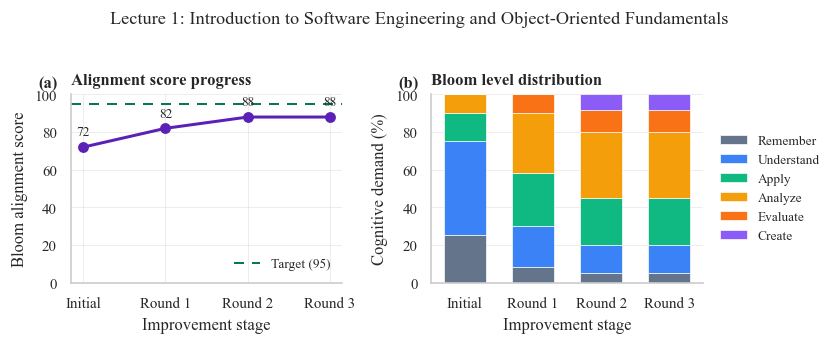


✓ Smoke test passed — continuing with remaining lectures

=== Step 4 Phase 2: remaining 9 lecture(s) ===

--- [2/10] Lecture 2. Inheritance, Polymorphism and Dynamic Binding ---
=== Step 1: generating outline for 'Lecture 2. Inheritance, Polymorphism and Dynamic Binding' ===
[outline] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.5, max_tokens=8192)...
    <- received response in 83.4s (20677 chars)
[outline] parsed valid JSON on attempt 1
=== Step 2: generating ~18 slides for 'Lecture 2: Inheritance, Polymorphism and Dynamic Binding' ===
[slides] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.6, max_tokens=8192)...
    <- received response in 106.1s (25632 chars)
[slides] parsed valid JSON on attempt 1
=== Step 3: evaluating 20 slides against Bloom's taxonomy ===
[evaluation] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.3, max_tokens=8192)...
    <- received response in 6

Saved Bloom figure: /Users/juliakotovich/Projects/lectura/output/course-generation/2025-mcsse-se-01/lectures/lecture-02-bloom-progress.pdf (+ .png 300dpi, .svg)


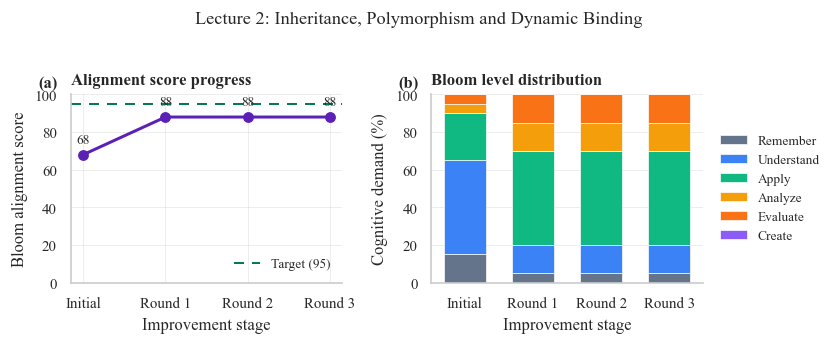


--- [3/10] Lecture 3. Genericity and Information Hiding ---
=== Step 1: generating outline for 'Lecture 3. Genericity and Information Hiding' ===
[outline] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.5, max_tokens=8192)...
    <- received response in 97.9s (24397 chars)
[outline] parsed valid JSON on attempt 1
=== Step 2: generating ~18 slides for 'Lecture 3: Genericity and Information Hiding' ===
[slides] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.6, max_tokens=8192)...
    <- received response in 137.0s (32763 chars)
[slides] attempt 1 failed to parse JSON: Expecting value: line 1 column 1 (char 0)
[slides] attempt 2/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.6, max_tokens=8192)...
    <- received response in 99.1s (25032 chars)
[slides] parsed valid JSON on attempt 2
=== Step 3: evaluating 18 slides against Bloom's taxonomy ===
[evaluation] attempt 1/3
    -> calling anth

Saved Bloom figure: /Users/juliakotovich/Projects/lectura/output/course-generation/2025-mcsse-se-01/lectures/lecture-03-bloom-progress.pdf (+ .png 300dpi, .svg)


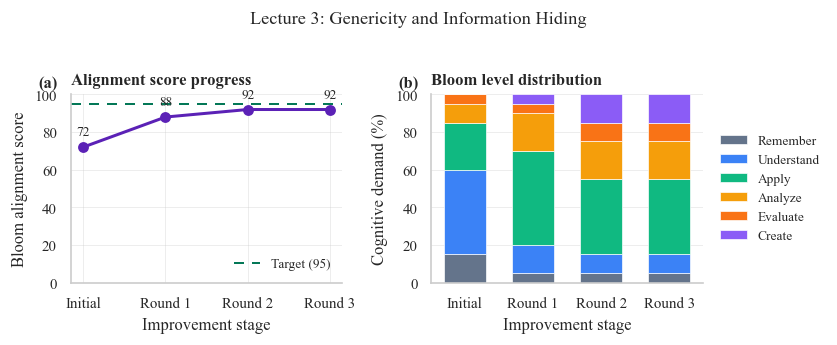


--- [4/10] Lecture 4. Design by Contract: Assertions and Program Correctness ---
=== Step 1: generating outline for 'Lecture 4. Design by Contract: Assertions and Program Correctness' ===
[outline] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.5, max_tokens=8192)...
    <- received response in 122.5s (28724 chars)
[outline] parsed valid JSON on attempt 1
=== Step 2: generating ~18 slides for 'Lecture 4. Design by Contract: Assertions and Program Correctness' ===
[slides] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.6, max_tokens=8192)...
    <- received response in 138.8s (31952 chars)
[slides] attempt 1 failed to parse JSON: Expecting value: line 1 column 1 (char 0)
[slides] attempt 2/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.6, max_tokens=8192)...
    <- received response in 127.6s (29626 chars)
[slides] parsed valid JSON on attempt 2
=== Step 3: evaluating 18 slides against 

Saved Bloom figure: /Users/juliakotovich/Projects/lectura/output/course-generation/2025-mcsse-se-01/lectures/lecture-04-bloom-progress.pdf (+ .png 300dpi, .svg)


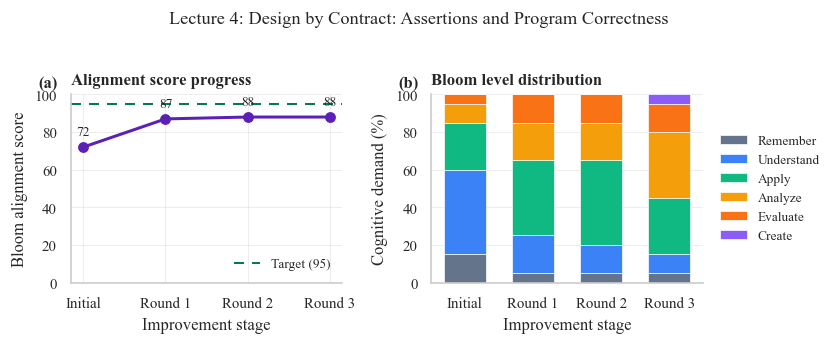


--- [5/10] Lecture 5. Fundamental Design Patterns I: Creational and Structural Patterns ---
=== Step 1: generating outline for 'Lecture 5. Fundamental Design Patterns I: Creational and Structural Patterns' ===
[outline] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.5, max_tokens=8192)...
    <- received response in 100.4s (25422 chars)
[outline] parsed valid JSON on attempt 1
=== Step 2: generating ~18 slides for 'Lecture 5. Fundamental Design Patterns I: Creational and Structural Patterns' ===
[slides] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.6, max_tokens=8192)...
    <- received response in 142.0s (34144 chars)
[slides] attempt 1 failed to parse JSON: Expecting value: line 1 column 1 (char 0)
[slides] attempt 2/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.6, max_tokens=8192)...
    <- received response in 107.8s (28749 chars)
[slides] parsed valid JSON on attempt 2
=== Step

Saved Bloom figure: /Users/juliakotovich/Projects/lectura/output/course-generation/2025-mcsse-se-01/lectures/lecture-05-bloom-progress.pdf (+ .png 300dpi, .svg)


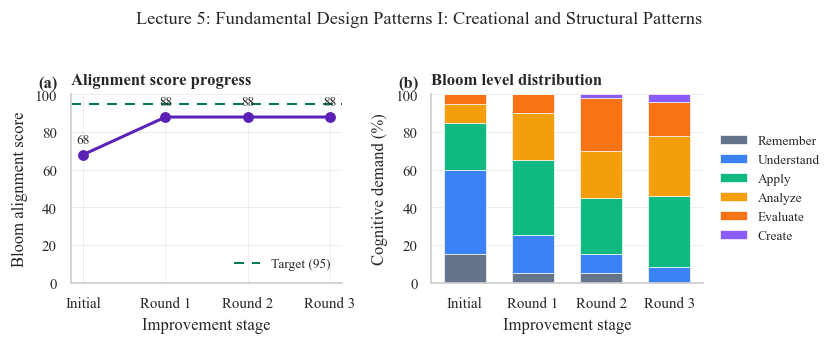


--- [6/10] Lecture 6. Fundamental Design Patterns II: Behavioral Patterns ---
=== Step 1: generating outline for 'Lecture 6. Fundamental Design Patterns II: Behavioral Patterns' ===
[outline] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.5, max_tokens=8192)...
    <- received response in 107.0s (27393 chars)
[outline] parsed valid JSON on attempt 1
=== Step 2: generating ~18 slides for 'Lecture 6. Fundamental Design Patterns II: Behavioral Patterns' ===
[slides] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.6, max_tokens=8192)...
    <- received response in 123.9s (31696 chars)
[slides] parsed valid JSON on attempt 1
=== Step 3: evaluating 19 slides against Bloom's taxonomy ===
[evaluation] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.3, max_tokens=8192)...
    <- received response in 51.1s (11518 chars)
[evaluation] parsed valid JSON on attempt 1
=== Step 3.5: improving 

Saved Bloom figure: /Users/juliakotovich/Projects/lectura/output/course-generation/2025-mcsse-se-01/lectures/lecture-06-bloom-progress.pdf (+ .png 300dpi, .svg)


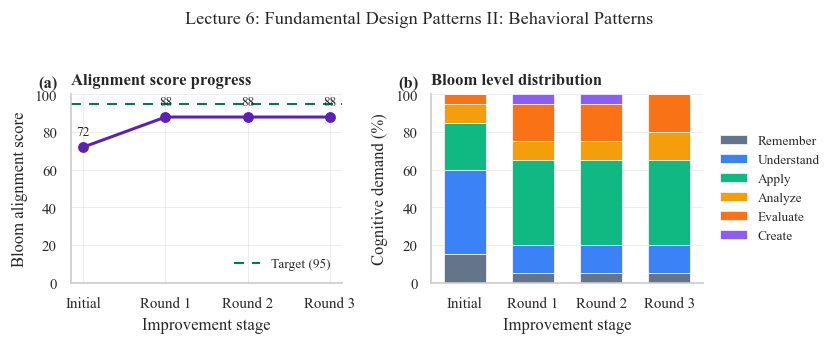


--- [7/10] Lecture 7. Software Architecture: Structuring Large-Scale Programs ---
=== Step 1: generating outline for 'Lecture 7. Software Architecture: Structuring Large-Scale Programs' ===
[outline] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.5, max_tokens=8192)...
    <- received response in 78.4s (19812 chars)
[outline] parsed valid JSON on attempt 1
=== Step 2: generating ~18 slides for 'Lecture 7. Software Architecture: Structuring Large-Scale Programs' ===
[slides] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.6, max_tokens=8192)...
    <- received response in 104.5s (25473 chars)
[slides] parsed valid JSON on attempt 1
=== Step 3: evaluating 18 slides against Bloom's taxonomy ===
[evaluation] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.3, max_tokens=8192)...
    <- received response in 56.9s (11800 chars)
[evaluation] parsed valid JSON on attempt 1
=== Step 3.5:

Saved Bloom figure: /Users/juliakotovich/Projects/lectura/output/course-generation/2025-mcsse-se-01/lectures/lecture-07-bloom-progress.pdf (+ .png 300dpi, .svg)


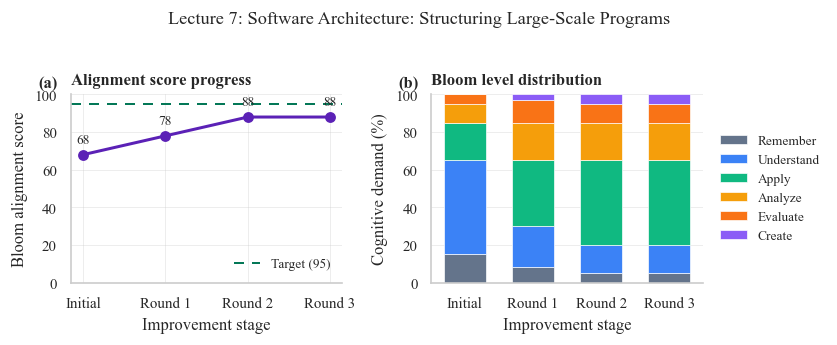


--- [8/10] Lecture 8. Requirements Engineering Fundamentals ---
=== Step 1: generating outline for 'Lecture 8. Requirements Engineering Fundamentals' ===
[outline] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.5, max_tokens=8192)...
    <- received response in 100.8s (24421 chars)
[outline] parsed valid JSON on attempt 1
=== Step 2: generating ~18 slides for 'Lecture 8: Requirements Engineering Fundamentals' ===
[slides] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.6, max_tokens=8192)...
    <- received response in 142.7s (32648 chars)
[slides] attempt 1 failed to parse JSON: Expecting value: line 1 column 1 (char 0)
[slides] attempt 2/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.6, max_tokens=8192)...
    <- received response in 119.2s (30363 chars)
[slides] parsed valid JSON on attempt 2
=== Step 3: evaluating 19 slides against Bloom's taxonomy ===
[evaluation] attempt 1/3
    -

Saved Bloom figure: /Users/juliakotovich/Projects/lectura/output/course-generation/2025-mcsse-se-01/lectures/lecture-08-bloom-progress.pdf (+ .png 300dpi, .svg)


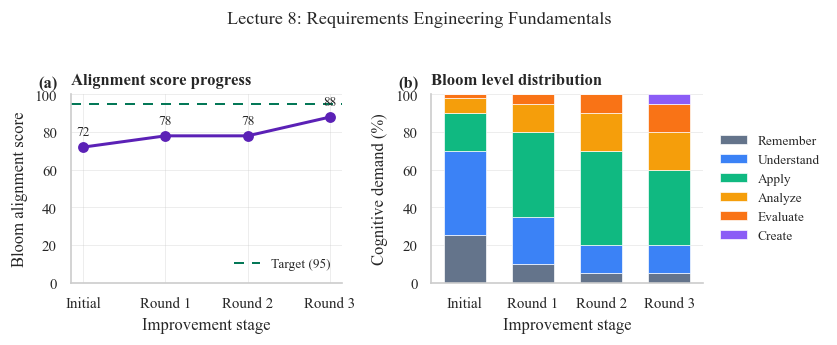


--- [9/10] Lecture 9. Agile Development Methods and Practices ---
=== Step 1: generating outline for 'Lecture 9. Agile Development Methods and Practices' ===
[outline] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.5, max_tokens=8192)...
    <- received response in 121.8s (26703 chars)
[outline] parsed valid JSON on attempt 1
=== Step 2: generating ~18 slides for 'Lecture 9: Agile Development Methods and Practices' ===
[slides] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.6, max_tokens=8192)...
    <- received response in 145.3s (31934 chars)
[slides] attempt 1 failed to parse JSON: Expecting value: line 1 column 1 (char 0)
[slides] attempt 2/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.6, max_tokens=8192)...
    <- received response in 143.7s (30646 chars)
[slides] parsed valid JSON on attempt 2
=== Step 3: evaluating 22 slides against Bloom's taxonomy ===
[evaluation] attempt 1/3

Saved Bloom figure: /Users/juliakotovich/Projects/lectura/output/course-generation/2025-mcsse-se-01/lectures/lecture-09-bloom-progress.pdf (+ .png 300dpi, .svg)


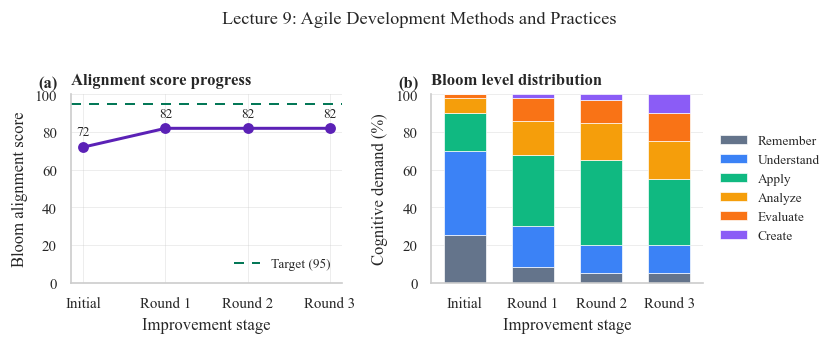


--- [10/10] Lecture 10. Software Engineering Process and Quality Assurance ---
=== Step 1: generating outline for 'Lecture 10. Software Engineering Process and Quality Assurance' ===
[outline] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.5, max_tokens=8192)...
    <- received response in 119.2s (31385 chars)
[outline] parsed valid JSON on attempt 1
=== Step 2: generating ~18 slides for 'Lecture 10: Software Engineering Process and Quality Assurance' ===
[slides] attempt 1/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.6, max_tokens=8192)...
    <- received response in 150.0s (32411 chars)
[slides] attempt 1 failed to parse JSON: Expecting value: line 1 column 1 (char 0)
[slides] attempt 2/3
    -> calling anthropic/claude-sonnet-4.5 via anthropic (temperature=0.6, max_tokens=8192)...
    <- received response in 146.6s (32792 chars)
[slides] attempt 2 failed to parse JSON: Expecting value: line 1 column 1 (char 0)
[slide

Saved Bloom figure: /Users/juliakotovich/Projects/lectura/output/course-generation/2025-mcsse-se-01/lectures/lecture-10-bloom-progress.pdf (+ .png 300dpi, .svg)


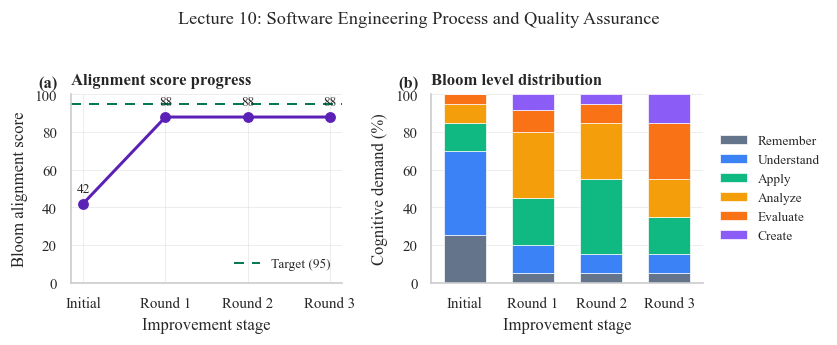

#,Lecture,Bloom init,Bloom final,Rounds
1,Introduction to Software Engineering and Object-Oriented Fundamentals,72,88,3
2,"Inheritance, Polymorphism and Dynamic Binding",68,88,3
3,Genericity and Information Hiding,72,92,3
4,Design by Contract: Assertions and Program Correctness,72,88,3
5,Fundamental Design Patterns I: Creational and Structural Patterns,68,88,3
6,Fundamental Design Patterns II: Behavioral Patterns,72,88,3
7,Software Architecture: Structuring Large-Scale Programs,68,88,3
8,Requirements Engineering Fundamentals,72,88,3
9,Agile Development Methods and Practices,72,82,3
10,Software Engineering Process and Quality Assurance,42,88,3


Saved full run artifacts.


In [14]:
# --- Step 4 settings ---
SLIDES_PER_LECTURE = 18  # target slides per lecture deck
SMOKE_TEST_FIRST = True  # run lecture 1 first; on success, auto-continue with the rest
MAX_LECTURES_TO_PROCESS = None  # full course (10 lectures); set 1 for smoke test only
AUTO_BLOOM_IMPROVE = True  # auto-loop improve until target score or max rounds
BLOOM_REEVALUATE_AFTER_IMPROVE = True  # same as UI default (reevaluate=True)
ENABLE_CQI = False  # Step 5 CQI v1 — disabled (extra LLM call per lecture)
GENERATE_PDF_REPORT = False  # set True to write generation-report.pdf


def build_lecture_description(lecture: dict, module: dict, course_context: str) -> str:
    topics = lecture.get("topics") or []
    lines = [
        f"Module: {module['name']} ({module['code']})",
        f"Lecture number: {lecture.get('number')}",
        f"Lecture title: {lecture.get('title')}",
        f"Duration: {lecture.get('durationMinutes', 90)} minutes",
    ]
    if lecture.get("summary"):
        lines.append(f"Lecture summary: {lecture['summary']}")
    if topics:
        lines.append("Lecture topics: " + "; ".join(topics))
    lines.extend(["", "Handbook / module context:", course_context[:8000]])
    return "\n".join(lines)


def lecture_artifact_paths(base_dir: Path, lecture_number: int) -> dict[str, Path]:
    prefix = base_dir / f"lecture-{lecture_number:02d}"
    return {
        "outline": Path(f"{prefix}-outline.json"),
        "deck": Path(f"{prefix}-deck.json"),
        "bloom": Path(f"{prefix}-bloom.json"),
        "improve_history": Path(f"{prefix}-improve-history.json"),
        "bloom_progress_figure": Path(f"{prefix}-bloom-progress"),
        "preview": Path(f"{prefix}-slide-bloom-preview.html"),
        "cqi": Path(f"{prefix}-cqi.json"),
    }


def save_full_run_markdown(run_bundle: dict, path: Path) -> None:
    plan = run_bundle["lecturePlan"]
    cqi = run_bundle.get("cqi") or {}
    enable_cqi = run_bundle.get("enableCqi", False)
    lines = [
        f"# Full run — {plan.get('moduleName')}",
        "",
        f"- **Module code:** {plan.get('moduleCode')}",
        f"- **Lectures processed:** {len(run_bundle['lectures'])}",
        f"- **Generated at:** {run_bundle['generatedAt']}",
        "",
    ]
    if enable_cqi:
        lines.extend([
            "## Course Quality Index (CQI v1)",
            "",
            f"- **CQI:** {cqi.get('courseQualityIndex', '—')} ({cqi.get('levelLabel', '—')})",
            f"- **Mean LRS:** {cqi.get('meanLectureReadiness', '—')}",
            f"- **Syllabus coverage:** {cqi.get('syllabusCoverage', '—')}%",
            f"- **Progression coherence:** {cqi.get('progressionCoherence', '—')}",
            f"- **Redundancy penalty:** {cqi.get('redundancyPenalty', '—')}",
            "",
        ])
    lines.extend([
        "## Bloom summary" if not enable_cqi else "## Bloom + CQI summary",
        "",
        "| # | Lecture | Bloom init | Bloom final | Rounds |"
        + (" LRS | CQI level |" if enable_cqi else ""),
        "|---|---------|------------|-------------|--------|"
        + ("-----|-----------|" if enable_cqi else "|"),
    ])
    for item in run_bundle["lectures"]:
        ev = item.get("evaluation") or {}
        cqi_lec = item.get("cqi") or {}
        row = (
            f"| {item['number']} | {item['title']} | {item.get('initialBloomScore', '—')} | "
            f"{ev.get('alignmentScore', '—')} | {item.get('improveRoundsUsed', 0)} |"
        )
        if enable_cqi:
            row = row.rstrip(" |") + (
                f" | {cqi_lec.get('lectureReadinessScore', '—')} | "
                f"{cqi_lec.get('levelLabel', '—')} |"
            )
        lines.append(row)
    lines.append("")
    for item in run_bundle["lectures"]:
        lines.append(f"## Lecture {item['number']}. {item['title']}")
        outline = item.get("outline") or {}
        ev = item.get("evaluation") or {}
        cqi_lec = item.get("cqi") or {}
        lines.append(f"- **Outline summary:** {outline.get('summary', '—')}")
        lines.append(f"- **Bloom:** {item.get('initialBloomScore', '—')} → {ev.get('alignmentScore', '—')}")
        if enable_cqi:
            lines.append(
                f"- **CQI LRS:** {cqi_lec.get('lectureReadinessScore', '—')} "
                f"(BA {cqi_lec.get('bloomAlignment', '—')}, OC {cqi_lec.get('objectiveCoverage', '—')}, "
                f"TC {cqi_lec.get('topicCoverage', '—')}, ALR {cqi_lec.get('activeLearningRatio', '—')}, "
                f"DQP {cqi_lec.get('deliveryQuality', '—')})"
            )
        gaps = ev.get("gaps") or []
        if gaps:
            lines.append("- **Bloom gaps:**")
            lines.extend(f"  - {g}" for g in gaps[:3])
        if enable_cqi:
            missing = (cqi_lec.get("engagement") or {}).get("missingTopics") or []
            if missing:
                lines.append("- **Missing topics:**")
                lines.extend(f"  - {t}" for t in missing[:3])
        lines.append("")
    path.write_text("\n".join(lines), encoding="utf-8")


def save_full_generation_report_pdf(run_bundle: dict, course_title: str, path: Path) -> None:
    FPDF = _ensure_fpdf()
    pdf = FPDF()
    pdf.set_auto_page_break(auto=True, margin=15)

    def heading(text: str, size: int = 13):
        pdf.ln(2)
        pdf.set_font("Helvetica", style="B", size=size)
        pdf.multi_cell(0, 8, pdf_safe(text), new_x="LMARGIN", new_y="NEXT")
        pdf.set_font("Helvetica", size=11)

    def body(text: str):
        pdf.multi_cell(0, 6, pdf_safe(text), new_x="LMARGIN", new_y="NEXT")

    plan = run_bundle["lecturePlan"]
    cqi = run_bundle.get("cqi") or {}
    enable_cqi = run_bundle.get("enableCqi", False)

    pdf.add_page()
    heading("Course Generation Algorithm - Full Report", 16)
    body(f"Generated: {run_bundle['generatedAt']}")
    body(f"Course section: {course_title}")
    body(f"Module: {plan.get('moduleName')} ({plan.get('moduleCode')})")

    if enable_cqi:
        heading("Course Quality Index (CQI v1)")
        body(f"CQI: {cqi.get('courseQualityIndex', '-')} / 100 ({cqi.get('levelLabel', '-')})")
        body(f"Mean lecture readiness (LRS): {cqi.get('meanLectureReadiness', '-')}")
        body(f"Syllabus coverage: {cqi.get('syllabusCoverage', '-')}%")
        body(f"Progression coherence: {cqi.get('progressionCoherence', '-')}")
        body(f"Redundancy penalty: {cqi.get('redundancyPenalty', '-')}")
        body("LRS weights: Bloom 35%, OC 25%, TC 20%, ALR 10%, DQP 10%")
        body("CQI weights: mean(LRS) 60%, syllabus 15%, progression 15%, non-redundancy 10%")

    heading("Step 0.5 - Lecture plan")
    body(f"Source: {plan.get('source')} | Lectures: {len(plan.get('lectures', []))}")
    for lec in plan.get("lectures", []):
        body(f"{lec.get('number')}. {lec.get('title')} ({lec.get('durationMinutes', 90)} min)")

    for item in run_bundle["lectures"]:
        pdf.add_page()
        heading(f"Lecture {item['number']}: {item['title']}")
        outline = item.get("outline") or {}
        ev = item.get("evaluation") or {}
        cqi_lec = item.get("cqi") or {}
        body(f"Slides: {item.get('slideCount', 0)}")
        body(f"Outline summary: {outline.get('summary', '-')}")
        body(
            f"Bloom: {item.get('initialBloomScore', '-')} -> {ev.get('alignmentScore', '-')} "
            f"| Improve rounds: {item.get('improveRoundsUsed', 0)}"
        )
        if enable_cqi:
            heading("CQI lecture breakdown", 12)
            body(f"LRS: {cqi_lec.get('lectureReadinessScore', '-')} ({cqi_lec.get('levelLabel', '-')})")
            body(f"  Bloom alignment (35%): {cqi_lec.get('bloomAlignment', '-')}")
            body(f"  Objective coverage (25%): {cqi_lec.get('objectiveCoverage', '-')}")
            body(f"  Topic coverage (20%): {cqi_lec.get('topicCoverage', '-')}")
            body(f"  Active learning ratio (10%): {cqi_lec.get('activeLearningRatio', '-')}")
            body(f"  Delivery quality (10%): {cqi_lec.get('deliveryQuality', '-')}")
            delivery = cqi_lec.get("delivery") or {}
            if delivery:
                body(f"  Avg words/slide: {delivery.get('avgWordsPerSlide', '-')} | Notes: {delivery.get('notesCoveragePct', '-')}%")
        gaps = ev.get("gaps") or []
        if gaps:
            body("Bloom gaps:")
            for gap in gaps[:4]:
                body(f"  - {gap}")
        if enable_cqi:
            missing_obj = (cqi_lec.get("engagement") or {}).get("missingObjectives") or []
            if missing_obj:
                body("Missing objectives:")
                for obj in missing_obj[:3]:
                    body(f"  - {obj}")

    path.parent.mkdir(parents=True, exist_ok=True)
    pdf.output(str(path))


def run_pipeline_for_all_lectures(
    lecture_plan: dict,
    module: dict,
    course_context: str,
    course_title: str,
    paths: dict[str, Path],
    *,
    slides_per_lecture: int = 18,
    max_lectures: int | None = None,
    smoke_test_first: bool = SMOKE_TEST_FIRST,
    auto_bloom_improve: bool = AUTO_BLOOM_IMPROVE,
    reevaluate_after_improve: bool = BLOOM_REEVALUATE_AFTER_IMPROVE,
) -> dict:
    enable_cqi = ENABLE_CQI
    plan_lectures = lecture_plan.get("lectures", [])
    total_in_plan = len(plan_lectures)
    if max_lectures is not None:
        plan_lectures = plan_lectures[:max_lectures]

    lectures_dir = paths["lectures_dir"]
    lectures_dir.mkdir(parents=True, exist_ok=True)

    run_items: list[dict] = []
    total_to_process = len(plan_lectures)

    def process_lectures(batch: list[dict], phase_label: str) -> None:
        nonlocal run_items
        print(phase_label)
        for lecture in batch:
            number = int(lecture.get("number") or len(run_items) + 1)
            title = lecture.get("title") or f"Lecture {number}"
            full_title = f"Lecture {number}. {title}"
            print(f"\n--- [{number}/{total_to_process}] {full_title} ---")

            description = build_lecture_description(lecture, module, course_context)
            outline = generate_outline(title=full_title, description=description, target_slides=slides_per_lecture)
            deck = generate_slides(outline, lecture_title=outline.get("title", full_title))
            slides = deck.get("slides", [])
            evaluation = evaluate_deck(
                lecture_title=outline.get("title", full_title),
                slides=slides,
                learning_objectives=outline.get("learningObjectives"),
            )
            initial_score = evaluation.get("alignmentScore")
            initial_evaluation = evaluation

            improve_result = run_bloom_improve_loop(
                lecture_title=outline.get("title", full_title),
                outline=outline,
                deck=deck,
                evaluation=evaluation,
                auto_improve=auto_bloom_improve,
                reevaluate=reevaluate_after_improve,
            )
            deck = improve_result["deck"]
            evaluation = improve_result["evaluation"]
            slides = deck.get("slides", [])

            cqi_metrics = None
            if enable_cqi:
                cqi_metrics = compute_lecture_cqi(
                    lecture_title=outline.get("title", full_title),
                    outline=outline,
                    deck=deck,
                    evaluation=evaluation,
                    planned_topics=lecture.get("topics") or [],
                )

            artifact_paths = lecture_artifact_paths(lectures_dir, number)
            artifact_paths["outline"].write_text(json.dumps(outline, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
            artifact_paths["deck"].write_text(json.dumps(deck, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
            artifact_paths["bloom"].write_text(json.dumps(evaluation, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
            artifact_paths["improve_history"].write_text(
                json.dumps(improve_result["improve_history"], indent=2, ensure_ascii=False) + "\n",
                encoding="utf-8",
            )
            if enable_cqi and cqi_metrics is not None:
                artifact_paths["cqi"].write_text(json.dumps(cqi_metrics, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
            save_slide_bloom_preview_html(
                deck=deck,
                bloom=evaluation,
                lecture_title=full_title,
                path=artifact_paths["preview"],
            )

            run_items.append(
                {
                    "number": number,
                    "title": title,
                    "outline": outline,
                    "deck": deck,
                    "evaluation": evaluation,
                    "cqi": cqi_metrics,
                    "initialBloomScore": improve_result.get("initial_score", initial_score),
                    "improveRoundsUsed": improve_result.get("rounds_used", 0),
                    "improveHistory": improve_result.get("improve_history", []),
                    "slideCount": len(slides),
                    "artifacts": {k: str(v) for k, v in artifact_paths.items()},
                }
            )

            progress = (
                f"Lecture {number} — Bloom {improve_result.get('initial_score', initial_score)} -> "
                f"{evaluation.get('alignmentScore')}"
            )
            if enable_cqi and cqi_metrics is not None:
                progress += (
                    f" | LRS {cqi_metrics.get('lectureReadinessScore')} "
                    f"({cqi_metrics.get('levelLabel')})"
                )
            show_title(progress, level=4)
            show_bloom_progress_charts(
                initial_evaluation=initial_evaluation,
                improve_result=improve_result,
                target_score=BLOOM_TARGET_SCORE,
                lecture_title=f"Lecture {number}: {title}",
                save_stem=artifact_paths["bloom_progress_figure"],
            )

    if smoke_test_first and len(plan_lectures) > 1 and max_lectures is None:
        process_lectures(plan_lectures[:1], "=== Step 4 Phase 1: smoke test (lecture 1) ===")
        print("\n✓ Smoke test passed — continuing with remaining lectures\n")
        process_lectures(
            plan_lectures[1:],
            f"=== Step 4 Phase 2: remaining {len(plan_lectures) - 1} lecture(s) ===",
        )
    else:
        process_lectures(plan_lectures, f"=== Step 4: processing {len(plan_lectures)} lecture(s) ===")

    course_cqi = compute_course_cqi(run_items, lecture_plan) if enable_cqi else None
    if enable_cqi and course_cqi:
        print(
            f"\n=== CQI v1: {course_cqi.get('courseQualityIndex')} ({course_cqi.get('levelLabel')}) "
            f"| mean LRS {course_cqi.get('meanLectureReadiness')} ==="
        )

    run_bundle = {
        "generatedAt": datetime.now(timezone.utc).isoformat(),
        "courseTitle": course_title,
        "lecturePlan": lecture_plan,
        "lectures": run_items,
        "enableCqi": enable_cqi,
        "cqi": course_cqi,
    }

    paths["full_run_json"].write_text(json.dumps(run_bundle, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    save_full_run_markdown(run_bundle, paths["full_run_markdown"])
    if GENERATE_PDF_REPORT:
        save_full_generation_report_pdf(run_bundle, course_title, paths["report_pdf"])

    return run_bundle


FULL_RUN = run_pipeline_for_all_lectures(
    lecture_plan=LECTURE_PLAN,
    module=selected_module,
    course_context=COURSE_CONTEXT,
    course_title=COURSE_TITLE,
    paths=LECTURE_PLAN_PATHS,
    slides_per_lecture=SLIDES_PER_LECTURE,
    max_lectures=MAX_LECTURES_TO_PROCESS,
)

show_title("Full run complete", level=3)
summary_fields = {
    "lectures_processed": len(FULL_RUN["lectures"]),
    "full_run_json": str(LECTURE_PLAN_PATHS["full_run_json"]),
    "full_run_markdown": str(LECTURE_PLAN_PATHS["full_run_markdown"]),
    "report_pdf": str(LECTURE_PLAN_PATHS["report_pdf"]) if GENERATE_PDF_REPORT else "(PDF disabled)",
    "lectures_dir": str(LECTURE_PLAN_PATHS["lectures_dir"]),
    "cqi_enabled": ENABLE_CQI,
}
if ENABLE_CQI and FULL_RUN.get("cqi"):
    summary_fields["cqi"] = (
        f"{FULL_RUN['cqi'].get('courseQualityIndex')} ({FULL_RUN['cqi'].get('levelLabel')})"
    )
show_fields(summary_fields)
table_headers = ["#", "Lecture", "Bloom init", "Bloom final", "Rounds"]
if ENABLE_CQI:
    table_headers.extend(["LRS", "Level"])
show_table(
    [
        [
            item["number"],
            item["title"],
            item.get("initialBloomScore"),
            item["evaluation"].get("alignmentScore"),
            item.get("improveRoundsUsed", 0),
        ]
        + (
            [
                (item.get("cqi") or {}).get("lectureReadinessScore"),
                (item.get("cqi") or {}).get("levelLabel"),
            ]
            if ENABLE_CQI
            else []
        )
        for item in FULL_RUN["lectures"]
    ],
    headers=table_headers,
)
print("Saved full run artifacts.")
